# Improving Performance

In the last session we developed Backpropagation and introduced some methods to improve our training speeds and accuracy. What we have introduced so far is the core of how backpropogation and training works, but we can now build on that considerably. Today we will look at two groups of methods that improve training. First, **alternative activation functions**: activations for output layers with several units (multi-label outputs and the softmax for multi-class outputs), and alternatives to the logistic function for hidden layers (tanh, ReLU and Leaky ReLU). Second, **optimizers**: the improvements to plain gradient descent (mini-batches, momentum and per-parameter learning rates) used by modern methods such as Adam.

Before we get going, let's just re-define some of our basic code definitions. This is all stuff we have introduced in previous weeks.

In [1]:
!pip3 install tf_keras==2.16
!pip3 install --upgrade tensorflow-hub

import os
os.environ['TF_USE_LEGACY_KERAS']='1'

In [2]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Standardization over 2D arrays
def standardize(x):
    col_means = np.mean(x,axis=0)
    col_std = np.std(x,axis=0)
    return (x - col_means) / col_std , col_means, col_std

# Linear Regression Function definition
def hLinear(theta_in,X_in):
    return np.matmul(theta_in,X_in)

def hLogistic(theta_in,X_in):
    z = np.matmul(theta_in,X_in)
    return 1 / (1 + np.exp(-z))

# Cost function for Linear regression
def cost_linear(theta,xi,yi):
    # note - this function calculate the cost for all variations of theta. A vector is returned.
    h = np.matmul(theta,xi)
    rv = ((h - yi)**2) / 2
    return rv

# The outer cost function 'J' calculator. This iterates over our training cases.
def J(theta,x,y,f):
    s = 0
    m = len(x)
    for i in range(0,m):
        v = f(theta,x[i],y[i])
        s+= v
    return s / m

# implementation of the gradient descent algorithm
def gd(theta_in,min_delta_in,a_in,X_in,Y_in,h,maxiterations=-1,cost=cost_linear):
    m = len(Y_in) # number of training examples
    _ , n = np.shape(X_in) # number of features

    # define a list used to store the costs - these do not have to be calculated but are useful for debugging
    c = []

    # Create a theta variable which we will use to keep track of the current value of theta
    theta = theta_in

    # Create a list which we will use for storing theta results during optimization
    thetas = np.array(theta_in,ndmin=2)

    # Create a counter which is used for limiting the number of iterations used if maxiterations has been defined
    k = 0

    # Begin main search loop
    while maxiterations is -1 or k < maxiterations:
        k+=1
        # log the cost - useful for visualisation and later analysis
        c.append(J(theta_in,X_in,Y_in,cost))

        # save a copy of the parameters -- this is the set we will read from
        temp = np.copy(theta)
        # iterate over all features -- remember though that we apply changes in parallel
        for j in range(0,n):
            # making calculations for jth parameter
            s = 0
            # calculate our gradient update over all training cases
            for i in range(0,m):
                s+=  (h(temp.T,np.ravel(X_in[i,:])) - Y_in[i])  * X_in[i,j]
            theta[j] = temp[j] - a_in * (1/m) * s

        # log the changed parameters
        thetas = np.vstack((thetas,theta))

        # not lets check to see if we are still making progress -- i.e., that our cost is reducing
        # we check to make sure that at least one of our parameters is changing by a minimum threshold
        progressing = False
        for j in range(0,n):
            if(abs(temp[j] - theta[j]) > min_delta_in):
                progressing = progressing | True
        if not progressing: break

    # if we have completed a maximum number of iterations -- or if we are no longer improving -- return
    return thetas, c

<>:54: SyntaxWarning: "is" with a literal. Did you mean "=="?
<>:54: SyntaxWarning: "is" with a literal. Did you mean "=="?
<>:54: SyntaxWarning: "is" with a literal. Did you mean "=="?
<>:54: SyntaxWarning: "is" with a literal. Did you mean "=="?
<ipython-input-2-a99bde03d3bf>:54: SyntaxWarning: "is" with a literal. Did you mean "=="?
  while maxiterations is -1 or k < maxiterations:
<ipython-input-2-a99bde03d3bf>:54: SyntaxWarning: "is" with a literal. Did you mean "=="?
  while maxiterations is -1 or k < maxiterations:


## A Running Example for this Session

The lecture covers two big ideas: **alternative activation functions** (for output layers and for hidden layers) and **optimizers**. Each idea is easy to understand on its own, but it is much more instructive to see what each one does to *the same problem*. So, alongside the material below, we will carry one working example through the whole notebook and change one thing at a time.

**The problem.** We use a classic *three spirals* dataset: points in 2D that belong to one of **three** classes, arranged as three interleaved spiral arms. This problem is useful for us for two reasons:
 * It has **more than two classes**, so we need an output layer with several units. That lets us compare the two ways of building such an output layer from the slides (independent logistic units vs. a softmax layer).
 * The class boundaries are strongly non-linear, so the network has to work hard. That makes differences between hidden-layer activation functions and between optimizers easy to see.

We train on 300 points (100 per class) and measure performance on a separate **test set** of 900 points that the network never trains on.

As we go through the notebook we will keep a scoreboard of results, building up step by step:

| Step | Section | What changes |
|---|---|---|
| 0 | Baseline | Logistic hidden units, 3 independent logistic outputs, plain gradient descent (last week's tools) |
| 1 | Output activations | Independent logistic outputs vs. a **softmax** output layer |
| 2 | Hidden activations | logistic vs. tanh vs. ReLU vs. Leaky ReLU, plus the dying ReLU problem |
| 3 | Optimizers | Gradient descent, mini-batch SGD, momentum, Adagrad, RMSProp, Adam |
| 4 | Putting it together | Combine the best of the above |

The example uses Keras, TensorFlow's high-level neural network library. For now, treat `build_net` and `fit_net` below as convenient wrappers around the forward and backward passes we have already implemented by hand.

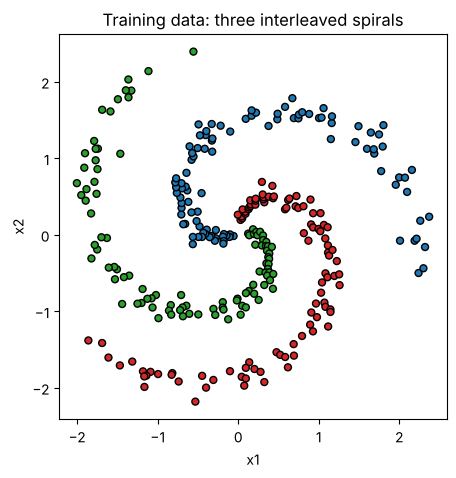

First three labels: [0 0 0]  as one-hot vectors:
 [[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]


In [2]:
# ---- Running example: data ----
import os
os.environ.setdefault('TF_USE_LEGACY_KERAS', '1')
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import tensorflow as tf

N_CLASSES = 3

def make_spirals(n_per_class, noise, seed):
    rng = np.random.default_rng(seed)
    X, y = [], []
    for k in range(N_CLASSES):
        r = np.linspace(0.05, 1, n_per_class)                       # radius grows along the arm
        t = np.linspace(k * 4, (k + 1) * 4, n_per_class) + rng.normal(0, noise, n_per_class)  # angle
        X.append(np.c_[r * np.sin(t), r * np.cos(t)])
        y += [k] * n_per_class
    return np.vstack(X).astype('float32'), np.array(y)

Xtr, ytr = make_spirals(100, 0.2, seed=1)    # training set: 300 points
Xte, yte = make_spirals(300, 0.2, seed=2)    # test set: 900 points, only used to measure performance

# Standardize using the TRAINING statistics only
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

# One-hot versions of the labels, e.g. class 2 -> [0, 0, 1]
Ytr = np.eye(N_CLASSES, dtype='float32')[ytr]
Yte = np.eye(N_CLASSES, dtype='float32')[yte]

CMAP = ListedColormap(['#d62728', '#1f77b4', '#2ca02c'])
plt.figure(figsize=(5, 5))
plt.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap=CMAP, edgecolor='k', s=25)
plt.title('Training data: three interleaved spirals'); plt.xlabel('x1'); plt.ylabel('x2')
plt.show()
print('First three labels:', ytr[:3], ' as one-hot vectors:\n', Ytr[:3])

Next we define a few helper functions that we will reuse in every step.

 * `build_net(...)` builds a fully connected network with **3 output units**, one per class. Its arguments are the things we will vary during the session: the hidden layer sizes, the hidden-layer `activation` and the `output` activation (`'sigmoid'` for independent logistic outputs or `'softmax'`). A fixed random `seed` means that, when we compare two settings, both networks start from the same initial weights.
 * `fit_net(...)` trains the network with a chosen optimizer. It picks the matching cross-entropy loss for the output layer (more on this below). By default it uses **full-batch** gradient descent (`batch_size = 300`, i.e. one weight update per epoch using all training data), which is the version of gradient descent we implemented ourselves.
 * `Logger` records, at the end of every epoch, the cross-entropy and accuracy on the training and test sets. It computes them in the same way for every network, so results are comparable across all experiments. Accuracy here means the fraction of points for which the output unit with the **largest** value is the correct class.
 * `plot_curves`, `plot_boundaries` and `record` handle plotting and the scoreboard.

In [3]:
# ---- Running example: helper functions ----
def leaky_relu(z):
    return tf.nn.leaky_relu(z, alpha=0.01)      # alpha = 0.01, as on the slides


def build_net(hidden=(32, 32), activation='relu', output='softmax', bias_init='zeros', seed=42):
    tf.keras.utils.set_random_seed(seed)                 # same initial weights for a fair comparison
    layers = [tf.keras.Input(shape=(2,))]
    for units in hidden:
        layers.append(tf.keras.layers.Dense(units, activation=activation, bias_initializer=bias_init))
    layers.append(tf.keras.layers.Dense(N_CLASSES, activation=output))
    model = tf.keras.Sequential(layers)
    model.output_kind = output
    return model


def _ce_acc(model, X, y):
    p = model(X, training=False).numpy()
    p = p / p.sum(axis=1, keepdims=True)      # softmax outputs already sum to 1; independent logistic outputs do not
    ce  = float(np.mean(-np.log(np.clip(p[np.arange(len(y)), y], 1e-7, 1))))
    acc = float(np.mean(p.argmax(axis=1) == y))
    return ce, acc


class Logger(tf.keras.callbacks.Callback):
    # Adds train/test cross-entropy and accuracy to the training history at the end of every epoch.
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        logs['train_ce'], logs['train_acc'] = _ce_acc(self.model, Xtr, ytr)
        logs['test_ce'],  logs['test_acc']  = _ce_acc(self.model, Xte, yte)


def fit_net(model, optimizer=None, epochs=300, batch_size=None, callbacks=None):
    optimizer = optimizer or tf.keras.optimizers.SGD(learning_rate=0.1)
    if model.output_kind == 'softmax':
        # categorical cross-entropy; the 'sparse' version takes integer labels (0, 1, 2) rather than one-hot vectors
        loss, targets = 'sparse_categorical_crossentropy', ytr
    else:
        # independent logistic outputs: binary cross-entropy for each output unit, averaged over the units
        loss, targets = 'binary_crossentropy', Ytr
    model.compile(optimizer=optimizer, loss=loss)
    start = time.perf_counter()
    hist = model.fit(Xtr, targets, epochs=epochs, verbose=0, shuffle=True,
                     batch_size=batch_size or len(Xtr),       # default = full-batch gradient descent
                     callbacks=[Logger()] + (callbacks or []))
    hist.seconds = time.perf_counter() - start
    return hist


def plot_curves(hists, keys=('train_ce',), title='', ylim=None, ax=None):
    ax = ax or plt.figure(figsize=(7, 4)).gca()
    styles = {'train_ce': '-', 'test_ce': '--', 'train_acc': '-', 'test_acc': '--'}
    for i, (name, h) in enumerate(hists.items()):
        for k in keys:
            ax.plot(h.history[k], styles.get(k, '-'), color=f'C{i}', label=f'{name} ({k})')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy' if 'ce' in keys[0] else 'Accuracy')
    if ylim: ax.set_ylim(*ylim)
    ax.set_title(title); ax.legend(fontsize=8)
    return ax


_g1, _g2 = np.meshgrid(np.linspace(-2.2, 2.2, 200), np.linspace(-2.2, 2.2, 200))
_grid = np.c_[_g1.ravel(), _g2.ravel()].astype('float32')

def plot_boundaries(models, ncols=4):
    n = len(models); ncols = min(ncols, n); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.5 * nrows), squeeze=False)
    for ax, (name, m) in zip(axes.ravel(), models.items()):
        cls = m(_grid, training=False).numpy().argmax(axis=1).reshape(_g1.shape)
        ax.contourf(_g1, _g2, cls, levels=[-0.5, 0.5, 1.5, 2.5], cmap=CMAP, alpha=0.3)
        ax.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap=CMAP, edgecolor='k', s=12)
        ax.set_title(f'{name}\ntrain acc {_ce_acc(m, Xtr, ytr)[1]:.2f} | test acc {_ce_acc(m, Xte, yte)[1]:.2f}', fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    for ax in axes.ravel()[n:]: ax.axis('off')
    plt.tight_layout(); plt.show()


results = {}   # the scoreboard we build up throughout the notebook

def record(name, model, hist=None):
    tr_ce, tr_acc = _ce_acc(model, Xtr, ytr)
    te_ce, te_acc = _ce_acc(model, Xte, yte)
    results[name] = {'train acc': tr_acc, 'test acc': te_acc, 'train loss': tr_ce, 'test loss': te_ce,
                     'train time (s)': hist.seconds if hist else None}
    print(f'{name:42s} train acc {tr_acc:.3f} | test acc {te_acc:.3f} | test loss {te_ce:.3f}')

### Running Example: Step 0, the Baseline
We start with the tools we had at the end of last week: two hidden layers of logistic units, trained with plain (full-batch) gradient descent and the cross-entropy loss. For three classes we simply use **three logistic output units**, one per class, each trained to output 1 for its own class and 0 otherwise. We predict the class whose output unit is largest.

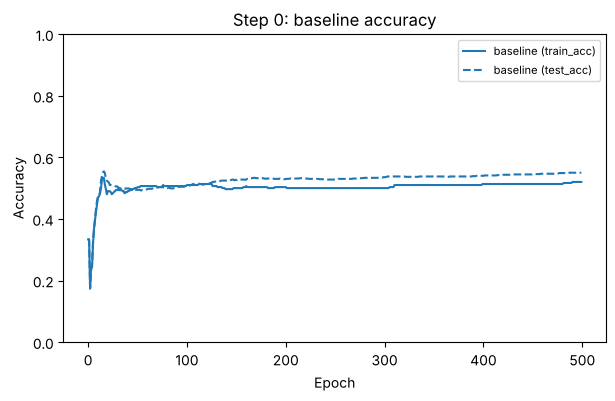

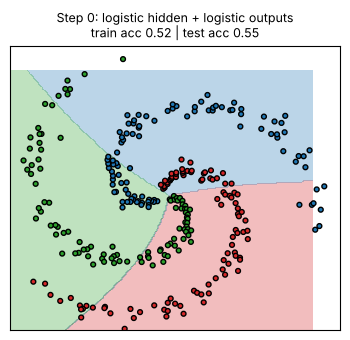

0. Baseline (logistic hidden & outputs, GD) train acc 0.520 | test acc 0.550 | test loss 0.745


In [4]:
base = build_net(hidden=(32, 32), activation='sigmoid', output='sigmoid')
h_base = fit_net(base, optimizer=tf.keras.optimizers.SGD(learning_rate=1.0), epochs=500)

plot_curves({'baseline': h_base}, keys=('train_acc', 'test_acc'), title='Step 0: baseline accuracy', ylim=(0, 1))
plt.show()
plot_boundaries({'Step 0: logistic hidden + logistic outputs': base})
record('0. Baseline (logistic hidden & outputs, GD)', base, h_base)

The baseline does better than guessing (which would give 0.33 accuracy), but its class regions are crude and do not follow the spirals. Over the rest of the notebook we will improve on this one step at a time.

---
## Activation Functions for Output Layers with Multiple Units

Until now our networks have had a **single** output unit. For binary classification, a logistic output unit with the cross-entropy loss works well: the output can be read as the probability of the positive class. Many problems need **several** output units, and then we must ask what the outputs mean. There are two quite different situations.

### Multi-label vs. Multi-class (Multinomial)
 * **Multi-label:** each example can have **any number** of positive labels at once. For example, an image might contain a *dog*, a *car* **and** a *tree*; a news article might be about *politics* and *economics*. The outputs are independent yes/no questions.
 * **Multi-class (multinomial):** each example has **exactly one** correct class out of several. For example, which digit is in an image, or which animal is in a photo. The outputs compete: if one is right, all the others must be wrong.

### Multi-label Outputs: Independent Logistic Units
For multi-label problems, we use one **logistic** output unit per label, exactly as for a single binary output, and treat each unit as a separate binary classifier. The loss is the cross-entropy for each output node, **averaged over all $K$ output nodes**:

\begin{equation}
L = -\frac{1}{K}\sum_{k=1}^{K} \Big[ y_k \log a_k + (1-y_k)\log(1-a_k) \Big]
\end{equation}

The error derivative is calculated **node by node**, and has the same simple form we derived last week for a single logistic output with cross-entropy:

\begin{equation}
\frac{\partial L}{\partial z_k} \propto a_k - y_k
\end{equation}

### Multi-class Outputs: Why Independent Logistic Units "Aren't Great"
We *can* use the same independent logistic units for a multi-class problem (that is what our baseline did), but it ignores what we know about the problem:
 * Nothing forces the outputs to add up to 1. The network might output 0.8, 0.2 and 0.1, which is not a probability distribution over the classes.
 * Each unit is trained separately, so the network is never directly told that the classes are mutually exclusive.

What we really want is to pick the largest output. However, the **max** (or **argmax**) function is not suitable as an activation function:
 1. It is **not differentiable**, so we cannot backpropagate through it. A tiny change to the inputs either changes nothing or flips the winner entirely.
 2. It does **not give a probability distribution** over all the outputs, only a single winner.

### The Softmax Activation Function
The **softmax** is a smooth, differentiable "soft" version of the max. For a layer with logits $z_1, \dots, z_K$, the activation of unit $k$ is

\begin{equation}
a_k = \text{softmax}(z)_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}
\end{equation}

 * Each $a_k$ is between 0 and 1, and the $a_k$ always **sum to 1**, so the outputs form a probability distribution over the classes.
 * Exponentiating exaggerates differences between logits, so the largest $z_k$ gets most of the probability. This is the "soft" max.

With a softmax output we use the **categorical cross-entropy** loss. Since exactly one $y_k$ is 1 (the correct class $c$), the loss reduces to the negative log probability given to the correct class:

\begin{equation}
L = -\sum_{k=1}^{K} y_k \log a_k = -\log a_c
\end{equation}

Remarkably, the derivative with respect to each logit takes exactly the same form as before:

\begin{equation}
\frac{\partial L}{\partial z_k} = a_k - y_k
\end{equation}

so backpropagation from a softmax layer is no harder than from a logistic layer.

**Where softmax is used.** Its basic use is as the output layer for multi-class classification. It is also used extensively *inside* more complex architectures. Most notably, the attention mechanism in transformers uses a softmax to turn a set of scores into weights that sum to 1.

Let us implement the softmax and look at how it behaves.

logits               : [2.  1.  0.1]
independent logistic : [0.881 0.731 0.525]  sum = 2.137
softmax              : [0.659 0.242 0.099]  sum = 1.0
hard max (one-hot)   : [1. 0. 0.]


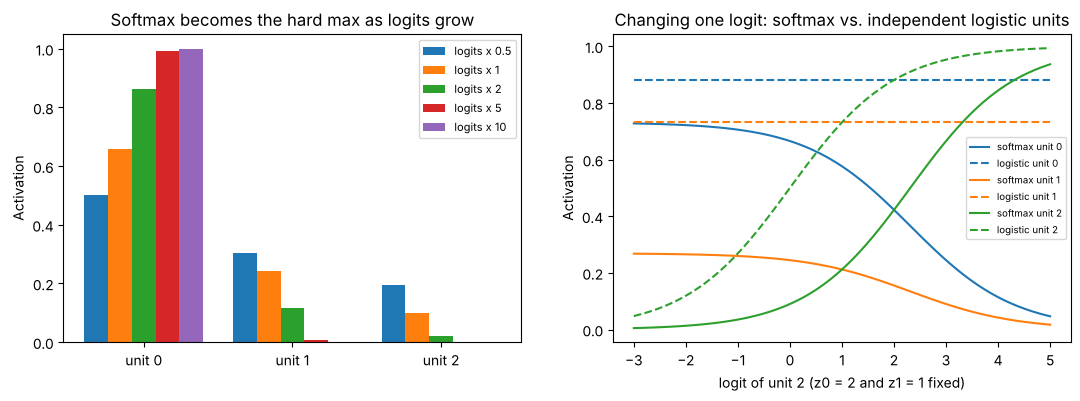

In [5]:
def logistic(z):
    return 1 / (1 + np.exp(-z))

def softmax(z):
    e = np.exp(z - np.max(z))       # subtracting the max avoids overflow and does not change the result
    return e / np.sum(e)

z = np.array([2.0, 1.0, 0.1])       # logits for three output units
print('logits               :', z)
print('independent logistic :', np.round(logistic(z), 3), ' sum =', round(logistic(z).sum(), 3))
print('softmax              :', np.round(softmax(z), 3), ' sum =', round(softmax(z).sum(), 3))
print('hard max (one-hot)   :', (z == z.max()).astype(float))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 1) Softmax as a "soft" max: scaling up the logits pushes the softmax towards the hard (one-hot) max
scales = [0.5, 1, 2, 5, 10]
for i, s in enumerate(scales):
    axes[0].bar(np.arange(3) + (i - 2) * 0.16, softmax(s * z), width=0.16, label=f'logits x {s}')
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(['unit 0', 'unit 1', 'unit 2'])
axes[0].set_ylabel('Activation'); axes[0].set_title('Softmax becomes the hard max as logits grow'); axes[0].legend(fontsize=8)

# 2) Are the softmax outputs independent of each other? Change only z[2] and watch all three outputs.
z2s = np.linspace(-3, 5, 100)
soft = np.array([softmax(np.array([2.0, 1.0, v])) for v in z2s])
log_ = np.array([logistic(np.array([2.0, 1.0, v])) for v in z2s])
for k in range(3):
    axes[1].plot(z2s, soft[:, k], color=f'C{k}', label=f'softmax unit {k}')
    axes[1].plot(z2s, log_[:, k], '--', color=f'C{k}', label=f'logistic unit {k}')
axes[1].set_xlabel('logit of unit 2 (z0 = 2 and z1 = 1 fixed)'); axes[1].set_ylabel('Activation')
axes[1].set_title('Changing one logit: softmax vs. independent logistic units'); axes[1].legend(fontsize=7)
plt.show()

The right-hand plot answers one of the questions on the slides. With independent logistic units (dashed lines), changing $z_2$ only changes unit 2. With softmax (solid lines), raising $z_2$ also *lowers* units 0 and 1, because the outputs share the denominator $\sum_j e^{z_j}$ and must always add up to 1. **Softmax outputs are not independent of each other.**

### Running Example: Step 1, Softmax Outputs
Our spirals problem is multi-class: every point belongs to exactly one spiral. So we keep everything from the baseline the same (logistic hidden units, gradient descent with the same learning rate, same initial hidden weights) and change only the output layer, from three independent logistic units to a **softmax** layer with the categorical cross-entropy loss.

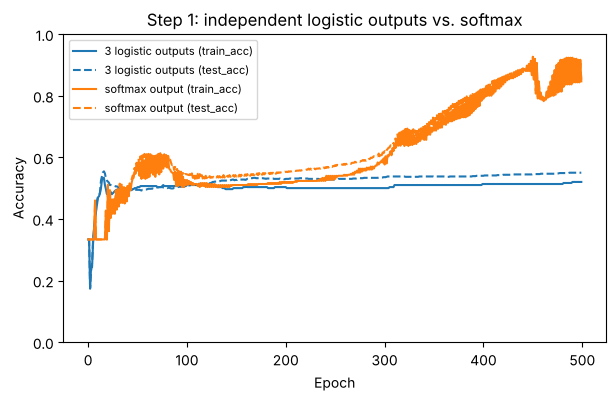

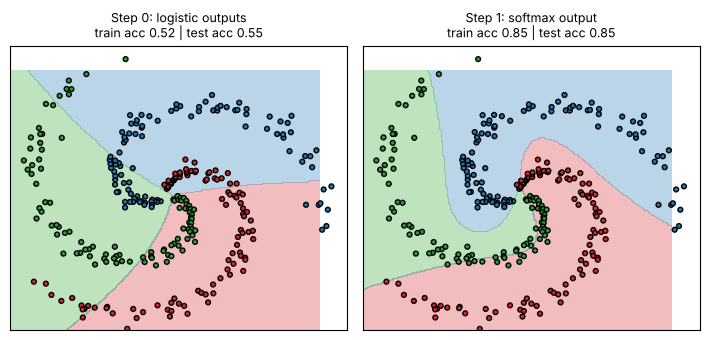

logistic outputs -> outputs: [[0.22, 0.32, 0.28], [0.23, 0.24, 0.35], [0.28, 0.26, 0.27]]  row sums: [0.82, 0.82, 0.81]
softmax output   -> outputs: [[0.31, 0.32, 0.37], [0.12, 0.59, 0.29], [0.47, 0.07, 0.46]]  row sums: [1.0, 1.0, 1.0]
1. Softmax output (logistic hidden, GD)    train acc 0.847 | test acc 0.852 | test loss 0.332


In [6]:
soft_net = build_net(hidden=(32, 32), activation='sigmoid', output='softmax')
h_soft = fit_net(soft_net, optimizer=tf.keras.optimizers.SGD(learning_rate=1.0), epochs=500)

plot_curves({'3 logistic outputs': h_base, 'softmax output': h_soft}, keys=('train_acc', 'test_acc'),
            title='Step 1: independent logistic outputs vs. softmax', ylim=(0, 1))
plt.show()
plot_boundaries({'Step 0: logistic outputs': base, 'Step 1: softmax output': soft_net})

# Look at the raw outputs of each network for the same three test points
for name, m in [('logistic outputs', base), ('softmax output  ', soft_net)]:
    out = m(Xte[[0, 300, 600]], training=False).numpy()
    print(name, '-> outputs:', np.round(out.astype(float), 2).tolist(), ' row sums:', np.round(out.sum(axis=1).astype(float), 2).tolist())
record('1. Softmax output (logistic hidden, GD)', soft_net, h_soft)

Changing only the output layer gives a large improvement in accuracy and a much better fit to the spiral shape. (The jagged softmax training curve is a sign that a learning rate of 1.0 is on the high side; we return to learning rates in the Optimizers section.) The printed outputs show the other difference: the softmax rows always sum to 1 and can be read directly as class probabilities, whereas the independent logistic outputs cannot.

From here on we use a **softmax output layer** for the running example.

---
## Other Activation Functions for Hidden Layers
Softmax and logistic units are mainly used at the **output** of a network, where we want probabilities. For the **hidden** layers there are better choices than the logistic function, as we see next.

## Hyperbolic Tangent Neurons
The switch to Cross Entropy Loss function last week was designed to speed up our laearning, but there are other ways in which we can speed up learning.

To this point our neural network examples have exclusively used the logistic neuron for hidden layers. This neuron is characterised by the logistic activation function:

\begin{equation}
g(z) = \frac{1}{1+ e^{-z}}
\end{equation}

and its derivative:

\begin{equation}
g'(z) = a\; (1-a)
\end{equation}

or more generally

\begin{equation}
g'(z) = \frac{e^{-z}}{ (1 + e^{-z})^2}
\end{equation}

where $z$ is the logit and defined as $z=\theta x$. But as mentioned previously other neuron types are possible.

All standard neurons differ in the definition of their activation function. In essence any activation function can be used so long as the activation function has a smooth derivative.

The Hyperbolic Tangent function or tanh, like the logistic function, is an example of a sigmoid function. The function is defined as:

\begin{equation}
g(z) = \frac{ e^{z} - e^{-z}}{e^{z} + e^{-z}}
\end{equation}

and its derivative is given by:

\begin{equation}
g'(z) = 1 - tanh^{2}(z)
\end{equation}

If we visualize the tanh function for a range of parameters we can see that it is broadly similar to the logistic function in form but has a range [-1,1] rather than [0,1] as is the case for the sigmoid.

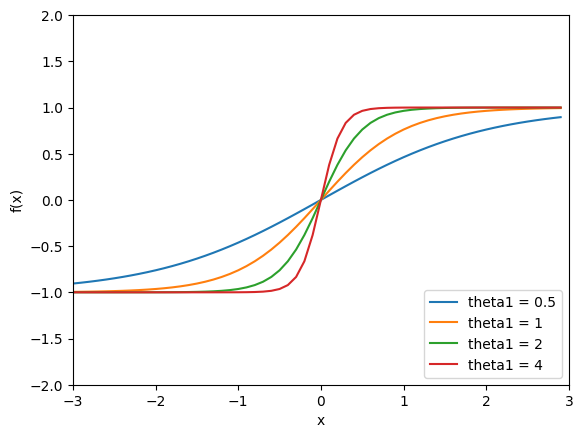

In [3]:
x1 = np.arange(-3,3,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z0 = np.matmul(np.array([0,0.5]),x)
z1 = np.matmul(np.array([0,1]),x)
z2 = np.matmul(np.array([0,2]),x)
z3 = np.matmul(np.array([0,4]),x)

plt.plot(x1,(np.exp(z0) - np.exp(-z0)) / (np.exp(z0) + np.exp(-z0)) )
plt.plot(x1,(np.exp(z1) - np.exp(-z1)) / (np.exp(z1) + np.exp(-z1)) )
plt.plot(x1,(np.exp(z2) - np.exp(-z2)) / (np.exp(z2) + np.exp(-z2)) )
plt.plot(x1,(np.exp(z3) - np.exp(-z3)) / (np.exp(z3) + np.exp(-z3)) )
plt.xlim([-3,3])
plt.ylim([-2,2])
plt.ylabel("f(x)")
plt.xlabel("x")
plt.legend(['theta1 = 0.5','theta1 = 1', 'theta1 = 2', 'theta1 = 4'], loc='lower right')
plt.show()

Tanh can also be interpreted as a rescaled sigmoid function (with a little horizontal stretching). We can see the two functions contrasted below.

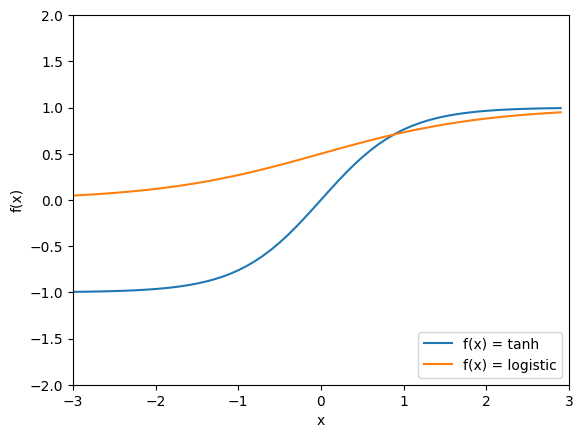

In [4]:
x1 = np.arange(-3,3,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z1 = np.matmul(np.array([0,1]),x)

plt.plot(x1,(np.exp(z1) - np.exp(-z1)) / (np.exp(z1) + np.exp(-z1)) )
plt.plot(x1,(1 / (1 + np.exp(-z1)) ) )
plt.xlim([-3,3])
plt.ylim([-2,2])
plt.ylabel("f(x)")
plt.xlabel("x")
plt.legend(['f(x) = tanh','f(x) = logistic'], loc='lower right')
plt.show()

As we can see from the above the slope of the tanh function is considerably more severe than the slope of the sigmoid function. Technically this means that the derivative of the tanh function has larger values than is the case for the logistic function for the same input values and model parameters. We can show that below numerically:

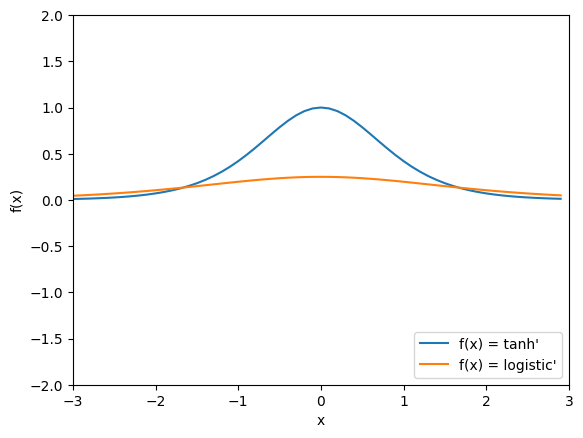

In [5]:
x1 = np.arange(-3,3,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z1 = np.matmul(np.array([0,1]),x)

plt.plot(x1,1 - (np.tanh(z1))**(2))
plt.plot(x1,np.exp(-z1) / (1 + np.exp(-z1))**2 )
plt.xlim([-3,3])
plt.ylim([-2,2])
plt.ylabel("f(x)")
plt.xlabel("x")
plt.legend(['f(x) = tanh\'','f(x) = logistic\''], loc='lower right')
plt.show()

In many sources it is noted that networks based on the tanh activation function tend to converge faster than is the case for networks based on the logistic activation function. This is primarily due to the more severe error surface slopes which allow error minima to be reached faster.

Regarding the faster convergence, we can investigate this empirically by comparing logistic and tanh performance.

To do this we first redefine our Backpropagation class, but in this case facilitate the selection of either logistic or hyperbolic tangent activation functions for our units. In doing this we need to provide implementations of the activation function itself for forward propagation and implementations of $g'(z)$ for back propagation. At this point we continue to use the squared error loss function for calculating overall error at the output layer of our network.

In [6]:
# In this implementation we force all vectors to be true 2D arrays with 1 column rather than
# numpy 1D arrays. This makes it easier to use matirx operations.

def celf_(y,a):
    if y == 1:
        return -np.log(a)
    elif y == 0:
        return -np.log(1-a)

celf = np.vectorize(celf_)

class Backpropogation:

    def __init__(self,x,y,s,cost="mse",a="tanh"):
        # set class references to X, Y, S and the activation function
        self.X = x
        self.Y = y
        self.S = s
        self.cost = cost
        if a == "logistic" or a == "tanh":
            self.activation = a
        else:
            raise ValueError("Unknown activation type " + str(a))
        # Define empty arrays for activation
        self.a     =  [None] * len(self.S)
        # Define empty array for z values (i.e., inputs)
        self.z     =  [None] * len(self.S)
        # Define empty arrays for weights
        self.theta =  [None] * len(self.S)
        # Define empty array for error derivitives for indivual units
        self.delta =  [None] * len(self.S)
        # Define empty arrays for accumulated errors on weights
        self.Delta =  [None] * len(self.S)

        # Initialize the weights for all layers
        for idx, val in enumerate(self.S):
            if idx == (len(self.S)-1): # ouput layer has no weights
                break
            self.theta[idx] = np.random.rand( self.S[idx]+1,self.S[idx+1])

    # Calculate the cost
    def calcCost(self,a,y):
        if self.cost == "mse":
            return np.sum(np.multiply(0.5,(a-y)**2))
        elif self.cost == "celf":
            return np.sum(celf(y,a))
        else: print("Error - no cost function selected")

    # calculate the activation values given an input
    def calcActivation(self,z):
        if self.activation == "logistic":
            return 1 / (1 + np.exp(-z))
        elif self.activation == "tanh":
            return np.tanh(z) # directly using numpy implementation
        else: print("Error - no activation function selected")

    # calculate ∂a/∂z
    def calcGPrimeZ(self,a):
        # Note that these implementations take advantage of the cached values for the activations
        # of each layer. if we did not have this cached values we would have to use the longer form
        # functions of z, i.e.,
        # 1 / (1 + exp(-z))
        # 1 - tanh(z)**2
        if self.activation == "logistic":
            return np.multiply(a,(1 - a))
        elif self.activation == "tanh":
            return 1.0 - a**2
        else: print("Error - no activation function selected")

    def forwardProp(self,x):
        # Forward propogate activation
        # For each layer from input to output
        for idx, val in enumerate(self.S):
            if idx == 0:
                # construct the activation values for the input layer from X and a bias value
                self.a[idx] = np.atleast_2d(np.hstack(([1.0],x))).T
            elif idx == (len(self.S)-1):
                # calculate z for the output layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate the activation values
                self.a[idx] = self.calcActivation(self.z[idx])
            else:
                # calculate z for a hidden layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate a for a hidden layer
                self.a[idx] = np.vstack(([1.0],self.calcActivation(self.z[idx])))
        # return the actual output values for the output layer
        return self.a[len(self.S)-1]

    def predict(self,X):
        results = []
        for datum in X:
            results.append(self.forwardProp(datum))
        return np.squeeze(results)

    def backwardProp(self,y):
        # For each layer from output to input
        for idx, val in reversed(list(enumerate(self.S))):
            if idx == (len(self.S)-1):
                if self.cost == "mse":
                    # calculate ∂a/∂z for the output layer
                    gprimez = self.calcGPrimeZ(self.a[idx])

                    # ∂E/∂zⱼ
                    self.delta[idx] = np.multiply(self.a[idx] - np.atleast_2d(y).T,gprimez)
                elif self.cost == "celf":
                    # ∂E/∂zⱼ
                    self.delta[idx] = -(np.atleast_2d(y).T - self.a[idx])
                else: print("Error - no cost function selected")
            elif idx == 0:
                # we need to update the weights in the 0th layer but we don't propogate error
                # derivitive back to the input units.
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T
            else:
                # calculate the error for all other layers

                # 1. calculate the derivitive of g(z)
                gprimez = self.calcGPrimeZ(self.a[idx])

                # 2. calculate the error associatd with each node in the current layer.
                self.delta[idx] = np.multiply(np.matmul(self.theta[idx],self.delta[idx+1]),gprimez)

                # get rid of the bias unit
                self.delta[idx] = self.delta[idx][1:,:]

                # 3. update the accumulated change
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T

        return self.calcCost(self.a[len(self.S)-1],np.atleast_2d(y).T)

    def train(self,epochs):
        errors = []
        # For each training epoch
        for k in range(epochs):
            error = 0
            # Initialize Delta for this epoch
            for idx, val in enumerate(self.S):
                if idx < (len(self.S)-1): # ouput layer has no weights
                    self.Delta[idx] = np.zeros((self.S[idx]+1,self.S[idx+1]))
            # Iterate over all training examples
            for i, y in enumerate(self.Y):
                self.forwardProp(self.X[i])
                error += self.backwardProp(y)
            errors.append(error)
            # For each layer from output to input
            for idx, val in reversed(list(enumerate(self.S))):
                if idx < (len(self.S)-1):
                    # Update the weights
                    self.theta[idx] = self.theta[idx] - (1/len(self.Y)) * self.Delta[idx]
        return errors

    def test(self):
        for i, y in enumerate(self.Y):
            output = self.forwardProp(self.X[i])
            print(self.X[i])
            print(y)
            print(output)
            print("Error is " + str(self.calcCost(output,np.atleast_2d(y).T)))
            print("---")

We can test our implementation for both logistic and tanh activation values.

Time taken for Logistic: 19.481473775999973


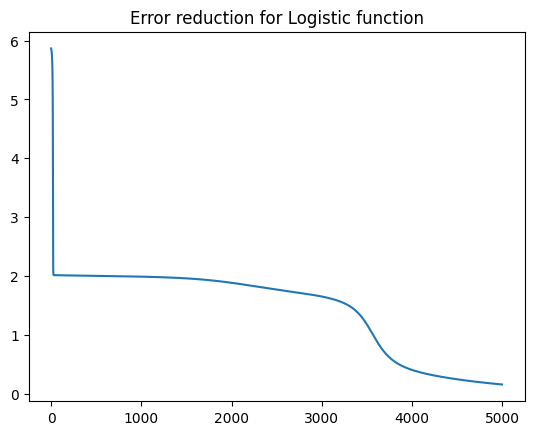

Time taken for Tanh: 7.993438150999964


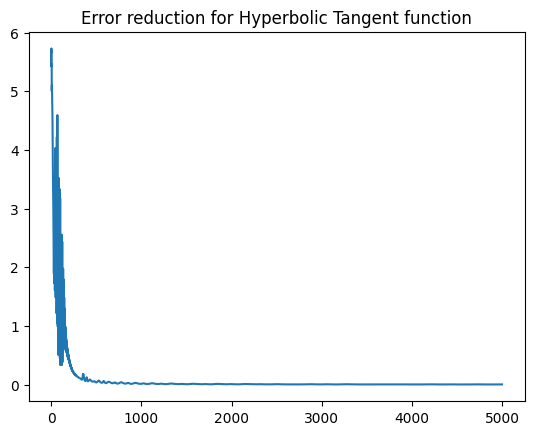

In [7]:
# Define the training data
Y = np.array([ 0,0,0,0,0,       1,1,1,  0,0,    1,1,1,     0,0,0,0,0])
X1 = np.array([4,6,1,9,1,       4,5,6,  9,1,    4,5,6,     9,1,9,4,6])
X2 = np.array([0,0,1,1,2,       2,2,2,  2,3,    3,3,3,     3,4,4,5,5])
X = np.vstack((X1,X2)).T

# standardize our input features
X, means, stds = standardize(X)

# Define the number of (visible) units in each layer
s = [2,8,8,1]

import time
start = time.perf_counter()
# Instantiate the network with data and topology, before running training
bp = Backpropogation(X,Y,s,cost="mse",a="logistic")
errors = bp.train(5000)
print("Time taken for Logistic: " + str(time.perf_counter() - start))

# Visualize Error over Epochs
fig = plt.figure()
plt.plot(errors)
plt.title("Error reduction for Logistic function")
plt.show()

start = time.perf_counter()
# Instantiate the network with data and topology, before running training
bp = Backpropogation(X,Y,s,cost="mse",a="tanh")
errors = bp.train(5000)
print("Time taken for Tanh: " + str(time.perf_counter() - start))

# Visualize Error over Epochs
plt.plot(errors)
plt.title("Error reduction for Hyperbolic Tangent function")
plt.show()

From the above we see three important things.

First it is clear that the tanh function converges on a good result much faster than the logistic implementation. By 500 iterations tanh has converged on a good result, while at 5000 iterations the logistic version has still not reached the same low value.

Also in terms of computational cost we see that the tanh implementation takes broadly the same amount of time as the logistic implementation. In fact the tanh implementation seems to narrowly outperform the logistic form over the same number of epochs.

The final note is that the tanh implementation does however seem to be less stable than the logistic function. there are wide jumps in error values for the first 500 iterations of the tanh activation. This is likely due to the more severe gradient of the tanh function leading our solution to jump around the cost space more. A reduction in learning rate would help to reduce this instability but this of course would then mean that the error minimum would have to be reached over a greater number of epochs.

Clearly the tanh activation function seems very useful. In practice however we still see that the logistic function is used frequently - particularly in example code. One reason for the prevalence of the logistic function is simply that it is so fundamental across Machine Learning and statistics. Logistic regression is based around the logistic function and neural networks are usually introduced as an extension of logistic regression.

It is worth noting that since the tanh function has output in [-1,1] rather than [0,1], it is not a natural fit for an output layer. For an output layer we will often use a different type of layer which specifically has outputs that are suitable to our problem at hand (remember for example the softmax function).

## Rectified Linear Neurons

Probably the most commonly encountered neuron in Deep Network implementations is the Rectified Linear Neuron or RELU. The Rectified Linear Neuron relies on a non-linear and non-symmetric activation function defined as:

\begin{equation}
  g(z) = max(0,z)
\end{equation}

i.e., g(z) returns the value z for any values of z above 0 and returns 0 for all other values. This can be visualized below.

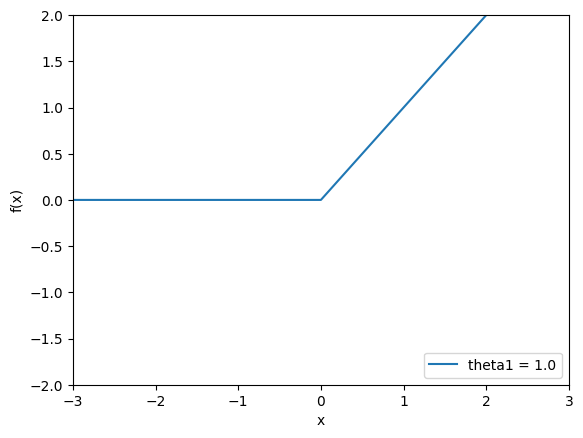

In [8]:
x1 = np.arange(-3,3,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z1 = np.matmul(np.array([0,1]),x)

plt.plot(x1,np.maximum(0,z1))
plt.xlim([-3,3])
plt.ylim([-2,2])
plt.ylabel("f(x)")
plt.xlabel("x")
plt.legend(['theta1 = 1.0'], loc='lower right')
plt.show()

We can see from the above that the Rectified Linear function has a very different profile to either Logistic or Tanh functions, and that unusual profile results in a derivative which unsurprisingly is not smooth.

The derivative of the Rectified Linear Unit can be characterized as being equal to 0 when $g(z) < 0$, 1 when $g(z) > 0$ and undefined where $g(z) = 0$. In practice we usually say that the derivative is 0 where $g(z) = 0$ though this is technically not true. Thus we can usually define $g'(z)$ as follows:

$
g'(z)=
\begin{cases}
0 & if \; g(z) <= 0\\
1 & if \; g(z) > 0
\end{cases}
$

A visualization of the derivative (given below) shows that this is essentially a step function.

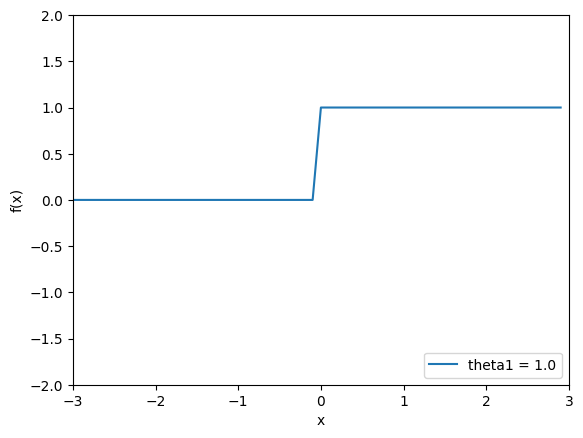

In [9]:
x1 = np.arange(-3,3,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z1 = np.matmul(np.array([0,1]),x)

def g(z):
    return 0 if z <= 0 else 1
g = np.vectorize(g)

plt.plot(x1,g(z1))
plt.xlim([-3,3])
plt.ylim([-2,2])
plt.ylabel("f(x)")
plt.xlabel("x")
plt.legend(['theta1 = 1.0'], loc='lower right')
plt.show()

Given the Rectified Linear Neuron seems to have such different properties to either the Tanh or Logistic units it can seem surprising that we can use it with gradient descent style optimization.

The fact that the Rectified Linear Neuron works at all can be understood as a consequence of one interpretation of the Rectified Linear Function. Essentially the Rectified Linear function can be interpreted as a summation of many different instances of logistic functions with different offsets. To see this we can simply total the results of the logistic for a number of different offsets and plot that against x.

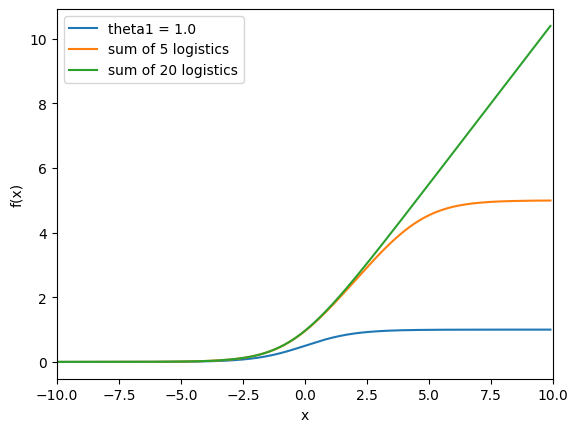

In [10]:
x1 = np.arange(-10,10,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z1 = np.matmul(np.array([0,1]),x)

def logistic(z):
    return 1 / (1 + np.exp(-z))

totals = np.zeros(len(x0))
totals2 = np.zeros(len(x0))
offsets = np.arange(0,5,1)
for o in offsets:
    totals = totals + logistic(z1 - o)

offsets = np.arange(0,20,1)
for o in offsets:
    totals2 = totals2 + logistic(z1 - o)

plt.plot(x1,logistic(z1))
plt.plot(x1,totals)
plt.plot(x1,totals2)
plt.xlim([-10,10])
plt.ylabel("f(x)")
plt.xlabel("x")
plt.legend(['theta1 = 1.0', 'sum of 5 logistics', 'sum of 20 logistics'], loc='upper left')
plt.show()

The actual summation of a number of different logistic units is given by the equation

\begin{equation}
g(z) = log(1 + e^{z})
\end{equation}

The rectified function is seen as a generalization of that function that does not require the calculation of the log or exponential function and is thus computationally easier to compute.

Clearly though the rectified function and its derivative are not computationally elegant in the normal sense. So the question remains, does it work despite this? The easiest way to determine this is to extend our implementation from above to include the Rectified Linear activation for forward propagation, and the derivative of this activation function with respect to the logit for back propagation.

In implementing Rectified Linear Units we must however pay attention to how we initialize the network. In short different activation functions prefer different forms of weight initialization. For the Rectified Linear Unit we should initialize the weights on our biases to 0 and evenly distribute the weight space for all other units between something like -0.5 and 0.5. We do this below by introducing different initializations for different types of layers.

In [11]:
# In this implementation we force all vectors to be true 2D arrays with 1 column rather than
# numpy 1D arrays. This makes it easier to use matirx operations.

def celf_(y,a):
    if y == 1:
        return -np.log(a)
    elif y == 0:
        return -np.log(1-a)

celf = np.vectorize(celf_)

class Backpropogation:

    def __init__(self,x,y,s,layers,cost="mse"):
        # set class references to X, Y, S and the activation function
        self.X = x
        self.Y = y
        self.S = s
        self.cost = cost
        if len(layers) == len(s) - 1:
            self.layers = ["None"] + layers
        else:
            raise ValueError("len(layers) != len(s) - 1")
        # Define empty arrays for activation
        self.a     =  [None] * len(self.S)
        # Define empty array for z values (i.e., inputs)
        self.z     =  [None] * len(self.S)
        # Define empty arrays for weights
        self.theta =  [None] * len(self.S)
        # Define empty array for error derivitives for indivual units
        self.delta =  [None] * len(self.S)
        # Define empty arrays for accumulated errors on weights
        self.Delta =  [None] * len(self.S)

        # Randomly Initialize the weights for all layers
        for idx, val in enumerate(self.S):
            if idx == (len(self.S)-1): # ouput layer has no weights
                break
            if layers[idx] == "tanh":
                self.theta[idx] = np.random.rand( self.S[idx]+1,self.S[idx+1]) - 0.5
            elif layers[idx] == "logistic":
                self.theta[idx] = np.random.rand( self.S[idx]+1,self.S[idx+1])
            elif layers[idx] == "relu":
                self.theta[idx] = np.random.rand( self.S[idx]+1,self.S[idx+1]) - 0.5
                self.theta[idx][0,:] = 0.0
            else:
                print("Error - unknown initialization for layer : " + layers[idx])

    # Calculate the cost
    def calcCost(self,a,y):
        if self.cost == "mse":
            return np.sum(np.multiply(0.5,(a-y)**2))
        elif self.cost == "celf":
            return np.sum(celf(y,a))
        else: print("Error - no cost function selected")

    # calculate the activation values given an input
    def calcActivation(self,z,activation):
        if activation == "logistic":
            return 1 / (1 + np.exp(-z))
        elif activation == "tanh":
            return np.tanh(z) # directly using numpy implementation
        elif activation == "relu":
            return np.maximum(0,z)
        else: print("Error - unknown activation function : " + str(activation))

    def calcGPrimeZ(self,a,activation):
        # Note that these implementations take advantage of the cached values for the activations
        # of each layer. if we did not have this cached values we would have to use the longer form
        # functions of z, i.e.,
        # 1 / (1 + exp(-z))
        # 1 - tanh(z)**2
        if activation == "logistic":
            return np.multiply(a,(1 - a))
        elif activation == "tanh":
            return 1.0 - a**2
        elif activation == "relu":
            temp = np.zeros(a.shape)
            temp[a > 0] = 1
            return temp
        else: print("Error - unknown activation function : " + str(activation))

    def forwardProp(self,x):
        # Forward propogate activation
        # For each layer from input to output
        for idx, val in enumerate(self.S):
            if idx == 0:
                # construct the activation values for the input layer from X and a bias value
                self.a[idx] = np.atleast_2d(np.hstack(([1.0],x))).T
            elif idx == (len(self.S)-1):
                # calculate z for the output layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate the activation values
                self.a[idx] = self.calcActivation(self.z[idx],self.layers[idx])
            else:
                # calculate z for a hidden layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate a for a hidden layer
                self.a[idx] = np.vstack(([1.0],self.calcActivation(self.z[idx],self.layers[idx])))
        # return the actual output values for the output layer
        return self.a[len(self.S)-1]

    def predict(self,X):
        results = []
        for datum in X:
            results.append(self.forwardProp(datum))
        return np.squeeze(results)

    def backwardProp(self,y):
        # For each layer from output to input
        for idx, val in reversed(list(enumerate(self.S))):
            if idx == (len(self.S)-1):
                if self.cost == "mse":
                    # calculate ∂a/∂z for the output layer
                    gprimez = self.calcGPrimeZ(self.a[idx],self.layers[idx])

                    # ∂E/∂zⱼ
                    self.delta[idx] = np.multiply(self.a[idx] - np.atleast_2d(y).T,gprimez)
                elif self.cost == "celf":
                    # ∂E/∂zⱼ
                    self.delta[idx] = -(np.atleast_2d(y).T - self.a[idx])
                else: print("Error - no cost function selected")
            elif idx == 0:
                # we need to update the weights in the 0th layer but we don't propogate error
                # derivitive back to the input units.
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T
            else:
                # calculate the error for all other layers

                # 1. calculate the derivitive of g(z)
                gprimez = self.calcGPrimeZ(self.a[idx],self.layers[idx])

                # 2. calculate the error associatd with each node in the current layer.
                self.delta[idx] = np.multiply(np.matmul(self.theta[idx],self.delta[idx+1]),gprimez)

                # get rid of the bias unit
                self.delta[idx] = self.delta[idx][1:,:]

                # 3. update the accumulated change
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T

        return self.calcCost(self.a[len(self.S)-1],np.atleast_2d(y).T)

    def train(self,epochs):
        errors = []
        # For each training epoch
        for k in range(epochs):
            error = 0
            # Initialize Delta for this epoch
            for idx, val in enumerate(self.S):
                if idx < (len(self.S)-1): # ouput layer has no weights
                    self.Delta[idx] = np.zeros((self.S[idx]+1,self.S[idx+1]))
            # Iterate over all training examples
            for i, y in enumerate(self.Y):
                self.forwardProp(self.X[i])
                error += self.backwardProp(y)
            errors.append(error)
            # For each layer from output to input
            for idx, val in reversed(list(enumerate(self.S))):
                if idx < (len(self.S)-1):
                    # Update the weights
                    self.theta[idx] = self.theta[idx] - (1/len(self.Y)) * self.Delta[idx]
        return errors

    def test(self):
        for i, y in enumerate(self.Y):
            output = self.forwardProp(self.X[i])
            print(self.X[i])
            print(y)
            print(output)
            print("Error is " + str(self.calcCost(output,np.atleast_2d(y).T)))
            print("---")

We can test our implementation by training the multivariate function as shown below.

Time taken for RELU training: 0.4062642459999779


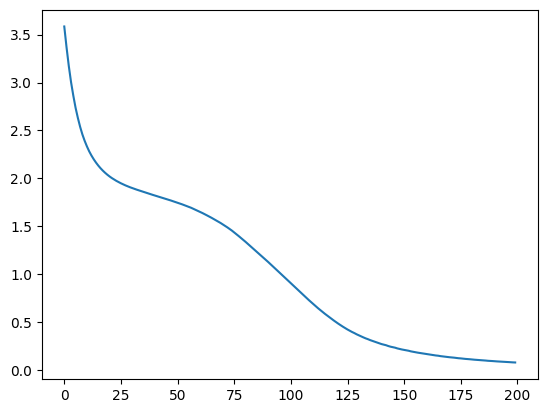

In [12]:
# Define the training data
Y = np.array([ 0,0,0,0,0,       1,1,1,  0,0,    1,1,1,     0,0,0,0,0])
X1 = np.array([4,6,1,9,1,       4,5,6,  9,1,    4,5,6,     9,1,9,4,6])
X2 = np.array([0,0,1,1,2,       2,2,2,  2,3,    3,3,3,     3,4,4,5,5])
X = np.vstack((X1,X2)).T

# standardize our input features
X, means, stds = standardize(X)

# Plot the training data in our usual way where the Target variable occupies the z-axis
fig = plt.figure()

# Define the number of (visible) units in each layer
s = [2,8,8,1]

# Define the layer types
layers = ["relu","relu","logistic"]

start = time.perf_counter()
# Instantiate the network with data and topology, before running training
bp = Backpropogation(X,Y,s,layers)
errors = bp.train(200)
print("Time taken for RELU training: " + str(time.perf_counter() - start))

# Visualize Error over Epochs
plt.plot(errors)
plt.show()

RELUs naturally lead to sparse activation. In a randomly initialized network half of the inputs to a unit will be less than 0 and hence half of the activation values will be null. This along with the 0 valued derivative means that more independent sub-networks tend to be learned. These sub-networks train on specific features of the input independently. Also the vanishing gradient problem - frequently troubling in very deep networks or recurrent networks - is less of an issue. For this reason the Rectified Linear Unit is currently the most popular unit basic unit type for Deep Learning.

As noted above, care must be taken with the initialization of Rectified Linear Unit weights. While our approach above will suffice for some examples the problem is relatively complex and was one of the reasons that pre-training of networks was required for Deep Neural Networks until recently. The change which allowed deep Rectified Linear Units to be applied has been credited to the Xavier algorithm which given the number of input and output units in a network performs an appropriate weight initialization for deep layers to ensure just enough signal propagates through the network. We do not go into the details of the Xavier algorithm here, but note that it is applied in practical Deep Neural Network implementations.

## Challenges with Rectified Linear Units: the Dying ReLU Problem

ReLU's derivative is exactly **0** for every negative input. If a unit's logit $z$ becomes negative for **every** example in the training data, then:
 * its output is 0 for every example, so it contributes nothing to the network, and
 * its gradient is 0 for every example, so its incoming weights **never change again**.

The unit has "died", and it is very hard for it to recover. This can happen when weights are initialised badly (for example close to 0 with negative biases), or when a **high learning rate** produces one large update that pushes the unit's weights and bias into the region where $z < 0$ for all inputs. In a badly affected network, a large fraction of the units can die, and the network loses much of its capacity.

## Beyond ReLU: Leaky ReLU
The **Leaky ReLU** keeps a small slope $\alpha$ for negative inputs instead of a flat zero:

\begin{equation}
g(z) = \begin{cases} z & \text{if } z > 0 \\ \alpha z & \text{if } z \le 0 \end{cases}
\qquad\qquad
g'(z) = \begin{cases} 1 & \text{if } z > 0 \\ \alpha & \text{if } z \le 0 \end{cases}
\end{equation}

where $\alpha$ is a small number, typically **0.01**. Because the gradient for negative inputs is small but **not zero**, a unit that has been pushed into the negative region can still receive updates and recover.

## Summary: Activation Functions for Hidden Layers

Backpropagation multiplies error signals by $g'(z)$ at **every** layer on the way back to the input, so the size of $g'(z)$ controls how fast learning happens and how quickly it fades as we go deeper:

| Activation | $g(z)$ | Output range | Max $g'(z)$ | Notes |
|---|---|---|---|---|
| Logistic | $\frac{1}{1+e^{-z}}$ | (0, 1) | **0.25** | Saturates for large $\lvert z\rvert$; outputs not zero-centred |
| Tanh | $\frac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | (-1, 1) | **1.0** | Zero-centred; still saturates for large $\lvert z\rvert$ |
| ReLU | $\max(0,z)$ | [0, ∞) | **1.0** (for all $z>0$) | No saturation for $z>0$; cheap; sparse activations; units can die |
| Leaky ReLU | $\max(\alpha z, z)$ | (-∞, ∞) | 1.0 | Small slope $\alpha$ for $z \le 0$, so units cannot die completely |

With logistic units, each layer can scale the error signal by *at most* 0.25. Through 5 layers that is at most $0.25^5 \approx 0.001$, so the layers near the input barely learn. This is the **vanishing gradient problem**. Tanh helps (its maximum slope is 1), but both functions *saturate*: for large $|z|$ the slope is almost 0. ReLU and Leaky ReLU have slope exactly 1 for every positive input.

The cell below first plots the derivatives together, and then measures the vanishing gradient problem directly. We build an 8-layer network with each activation, pass the training data through it once, and measure the size of the gradient for each layer's weights *before any training*.

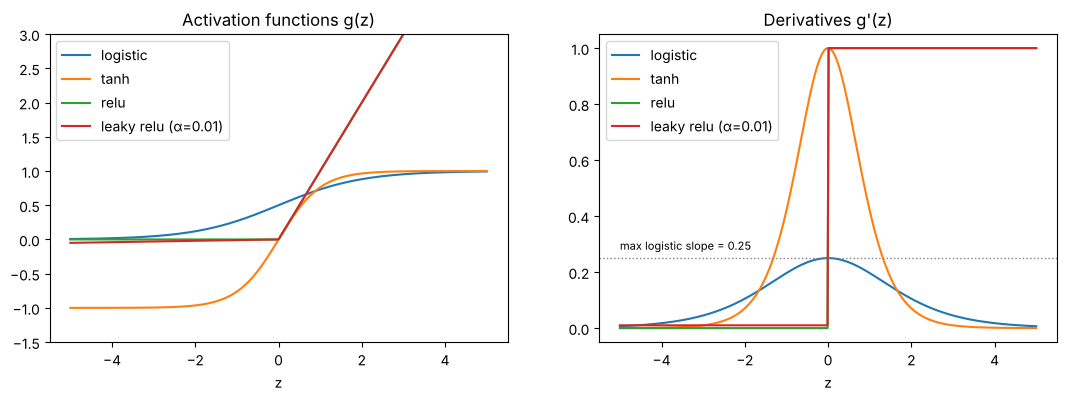

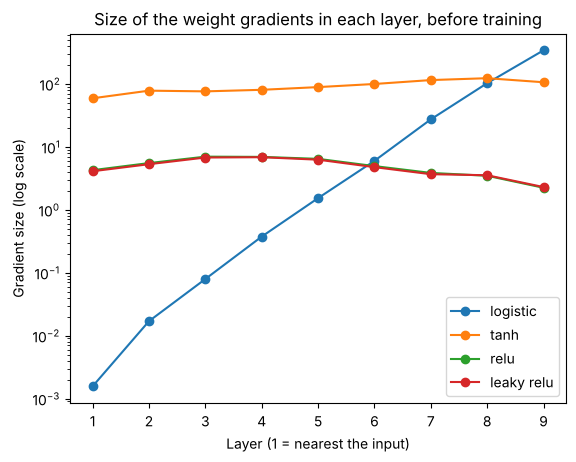

In [7]:
z = np.linspace(-5, 5, 400)
sig = 1 / (1 + np.exp(-z))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, g, d in [('logistic', sig, sig * (1 - sig)),
                   ('tanh', np.tanh(z), 1 - np.tanh(z) ** 2),
                   ('relu', np.maximum(0, z), (z > 0).astype(float)),
                   ('leaky relu (α=0.01)', np.where(z > 0, z, 0.01 * z), np.where(z > 0, 1.0, 0.01))]:
    axes[0].plot(z, g, label=name); axes[1].plot(z, d, label=name)
axes[0].set_ylim(-1.5, 3); axes[0].set_title('Activation functions g(z)'); axes[0].legend()
axes[1].axhline(0.25, color='grey', ls=':', lw=1); axes[1].text(-5, 0.28, 'max logistic slope = 0.25', fontsize=8)
axes[1].set_title("Derivatives g'(z)"); axes[1].legend()
for ax in axes: ax.set_xlabel('z')
plt.show()

# Vanishing gradients: gradient size per layer at initialisation in a deep (8 hidden layer) network
deep_grads = {}
for name, act in [('logistic', 'sigmoid'), ('tanh', 'tanh'), ('relu', 'relu'), ('leaky relu', leaky_relu)]:
    net = build_net(hidden=(32,) * 8, activation=act)
    with tf.GradientTape() as tape:
        loss = tf.keras.losses.sparse_categorical_crossentropy(ytr, net(Xtr))
    grads = tape.gradient(loss, net.trainable_variables)
    deep_grads[name] = [float(tf.norm(gr)) for gr in grads[0::2]]   # kernels only (skip the biases)

for name, gs in deep_grads.items():
    plt.plot(range(1, len(gs) + 1), gs, 'o-', label=name)
plt.yscale('log'); plt.xlabel('Layer (1 = nearest the input)'); plt.ylabel('Gradient size (log scale)')
plt.title('Size of the weight gradients in each layer, before training'); plt.legend(); plt.show()

Note the log scale. With logistic units the gradient shrinks by orders of magnitude between the output layer and the first layer, so the early layers hardly learn at all. Tanh, ReLU and Leaky ReLU keep the gradient at a similar size through the whole network.

### Running Example: Step 2, Comparing Hidden-Layer Activation Functions
Now we train the same deeper network (4 hidden layers of 32 units, softmax output) on the spirals with each hidden activation. Everything else is held fixed: the same data, the same plain gradient descent with the same learning rate, and the same number of epochs. We use plain gradient descent rather than a modern optimizer because, as we will see later, optimizers such as Adam partly *compensate* for small gradients, which would hide the differences we want to see.

logistic   training time: 10.8s


tanh       training time: 8.9s


relu       training time: 10.8s


leaky relu training time: 9.3s


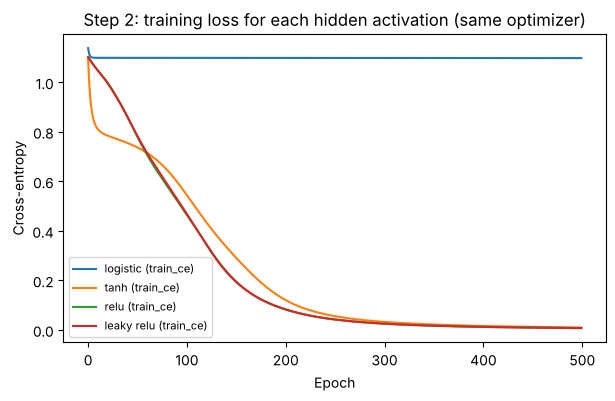

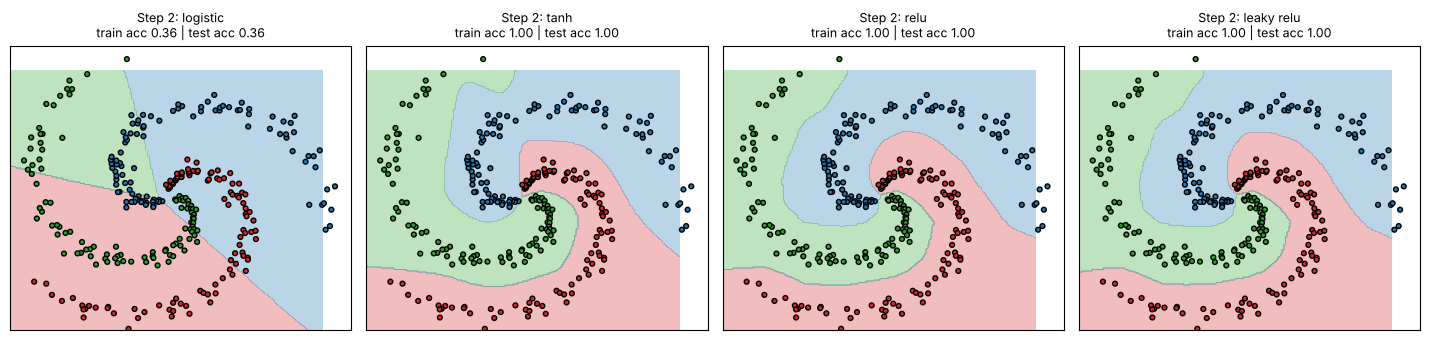

2. Hidden activation = logistic (GD)       train acc 0.357 | test acc 0.360 | test loss 1.098
2. Hidden activation = tanh (GD)           train acc 1.000 | test acc 0.997 | test loss 0.020
2. Hidden activation = relu (GD)           train acc 1.000 | test acc 0.997 | test loss 0.037
2. Hidden activation = leaky relu (GD)     train acc 1.000 | test acc 0.997 | test loss 0.039


In [8]:
acts = {'logistic': 'sigmoid', 'tanh': 'tanh', 'relu': 'relu', 'leaky relu': leaky_relu}
act_models, act_hists = {}, {}
for name, act in acts.items():
    m = build_net(hidden=(32, 32, 32, 32), activation=act)
    act_hists[name] = fit_net(m, optimizer=tf.keras.optimizers.SGD(learning_rate=0.1), epochs=500)
    act_models[name] = m
    print(f'{name:10s} training time: {act_hists[name].seconds:.1f}s')

plot_curves(act_hists, title='Step 2: training loss for each hidden activation (same optimizer)')
plt.show()
plot_boundaries({f'Step 2: {a}': m for a, m in act_models.items()})
for a, m in act_models.items():
    record(f'2. Hidden activation = {a} (GD)', m, act_hists[a])

You should see that the deep logistic network does not learn at all: it stays at a loss of about 1.1, which is $-\log(1/3)$, the loss of a network that gives every class a probability of one third. The deep stack of logistic units passes back almost no error signal, which is exactly the vanishing gradient effect we measured above. Tanh, ReLU and Leaky ReLU all learn the spirals. ReLU is also the cheapest to compute, which is one of the reasons it became the default choice for hidden layers.

### Seeing the Dying ReLU Problem
In the comparison above, ReLU and Leaky ReLU behave almost identically, because the network was initialised sensibly and the learning rate was moderate. To *see* the dying ReLU problem we deliberately create the bad situation the slides describe: we start every hidden unit with a bias of **-1**, so that most units start with $z < 0$ for every training point.

We train a network with a single hidden layer of 32 units using ReLU and using Leaky ReLU, and after every epoch we count the fraction of **dead** units: units whose logit is negative for **all** training points.

relu       dead units at the start: 84%


relu       dead units at the end:   94%
leaky relu dead units at the start: 84%


leaky relu dead units at the end:   9%


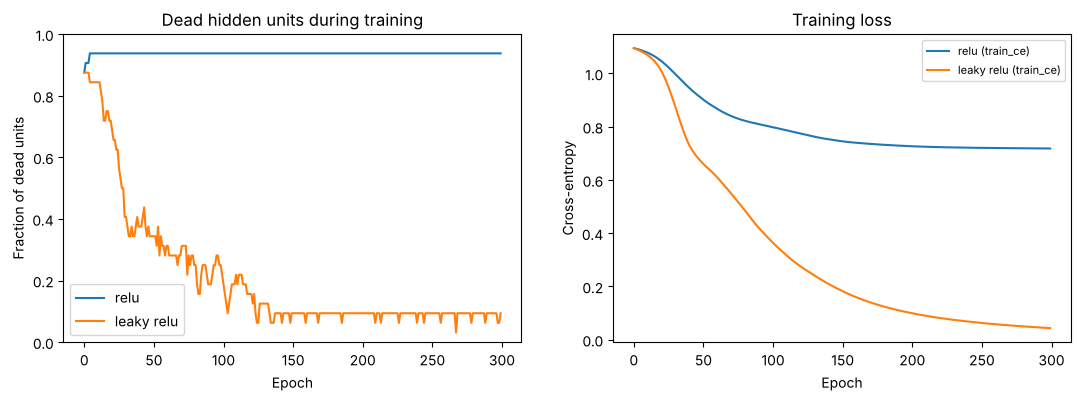

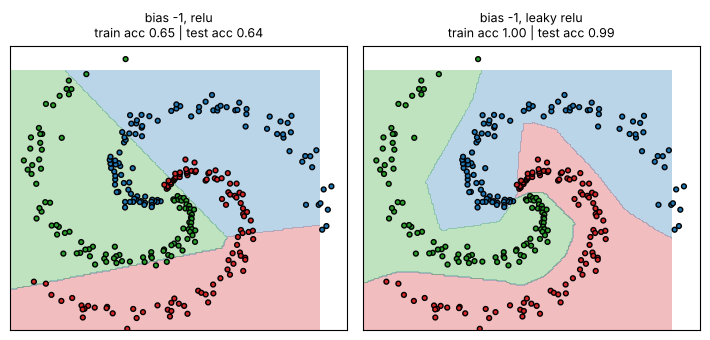

In [9]:
def dead_fraction(model):
    # fraction of units in the first hidden layer whose logit z is <= 0 for every training example
    W, b = model.layers[0].get_weights()
    z = Xtr @ W + b
    return float(np.mean((z <= 0).all(axis=0)))

class DeadUnitLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs['dead'] = dead_fraction(self.model)

dying_models, dying_hists = {}, {}
for name, act in [('relu', 'relu'), ('leaky relu', leaky_relu)]:
    m = build_net(hidden=(32,), activation=act, bias_init=tf.keras.initializers.Constant(-1.0))
    print(f'{name:10s} dead units at the start: {dead_fraction(m):.0%}')
    dying_hists[name] = fit_net(m, optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), epochs=300,
                                callbacks=[DeadUnitLogger()])
    dying_models[name] = m
    print(f'{name:10s} dead units at the end:   {dead_fraction(m):.0%}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (name, h) in enumerate(dying_hists.items()):
    axes[0].plot(h.history['dead'], color=f'C{i}', label=name)
axes[0].set_ylim(0, 1); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Fraction of dead units')
axes[0].set_title('Dead hidden units during training'); axes[0].legend()
plot_curves(dying_hists, title='Training loss', ax=axes[1])
plt.show()
plot_boundaries({f'bias -1, {k}': m for k, m in dying_models.items()})

With ReLU, the units that start out dead receive no gradient and **stay dead**. A few more units die during training, and the network is left with only a handful of working units, so it cannot fit the spirals. With Leaky ReLU, the same units still receive a small gradient through the $\alpha z$ slope. They are gradually pulled back into the active region, and the network recovers and learns the problem.

**ReLU vs. Leaky ReLU in practice.** Despite this, **ReLU is still the default** choice for hidden layers. In practice the dying ReLU problem is usually better addressed by good weight initialisation and careful control of the learning rate (keeping it low enough to avoid huge updates) than by changing the activation function. Leaky ReLU is a useful alternative when you see many dead units.

## Optimizers for Training

So far we have mostly used plain gradient descent, and treated the optimizer as a black box. We now look inside it. The goal of every optimizer is the same: **reduce the error over time** by moving the weights downhill on the error surface. They differ in *how* they choose each step.

### Problems with Full (Batch) Gradient Descent
Plain gradient descent computes the gradient over the *whole* training set and then takes one step:

\begin{equation}
\theta \leftarrow \theta - \alpha \nabla_\theta J(\theta)
\end{equation}

This has three practical problems:
 1. **Choosing the learning rate $\alpha$.** If $\alpha$ is too small, progress is painfully slow. If it is too large, we overshoot the minimum, oscillate or even diverge. A single $\alpha$ that suits every direction of the error surface rarely exists.
 2. **Meandering.** On error surfaces shaped like long, narrow valleys (very common in neural networks), the gradient points mostly *across* the valley rather than along it, so gradient descent zig-zags from side to side and makes slow progress towards the minimum.
 3. **Local minima and plateaus.** The gradient is zero (or close to it) in local minima, saddle points and flat regions, so gradient descent can stall there.

It is also expensive: we must process the whole dataset to make a single update.

### Solutions
 * **Stochastic Gradient Descent (SGD):** update the weights after *each individual example*. Updates are much more frequent, and the noise in them can help to jump out of shallow local minima, but they are noisy and we lose the efficiency of matrix operations.
 * **Mini-batch SGD:** the happy middle ground. Average the gradient over a small batch (e.g. 16 to 512 examples) and then update. This is what `batch_size` controls in Keras, and it is what "SGD" almost always means in practice.
 * **Adjustable (decaying) learning rates:** take large steps early and smaller steps as we approach a minimum (e.g. Keras learning-rate schedules).
 * **Momentum:** keep a running "velocity" that accumulates past gradients, like a ball rolling downhill:

\begin{align}
v &\leftarrow \beta v - \alpha \nabla_\theta J(\theta) \\
\theta &\leftarrow \theta + v
\end{align}

  Components of the gradient that keep pointing the same way (along the valley floor) build up speed, while components that flip sign (across the valley) cancel out. Momentum also helps to roll *through* small local minima. A typical value is $\beta = 0.9$.
 * **Feature-specific (per-parameter) learning rates:** give each weight its own effective learning rate, depending on the history of its gradients.
   * **Adagrad** divides each weight's step by the square root of the sum of all its past squared gradients, $\theta_i \leftarrow \theta_i - \frac{\alpha}{\sqrt{G_i}+\epsilon} g_i$. Weights with consistently large gradients get smaller steps. However, $G_i$ only ever grows, so learning can grind to a halt.
   * **RMSProp** fixes this by using an exponentially decaying *average* of squared gradients instead of their sum: $s_i \leftarrow \rho s_i + (1-\rho) g_i^2$, then $\theta_i \leftarrow \theta_i - \frac{\alpha}{\sqrt{s_i}+\epsilon} g_i$.
   * **Adam** (Adaptive Moment Estimation) combines **momentum** (a running average of gradients, $m$) with **RMSProp-style scaling** (a running average of squared gradients, $s$), plus a correction for the fact that both start at zero:

\begin{align}
m &\leftarrow \beta_1 m + (1-\beta_1) g, \qquad s \leftarrow \beta_2 s + (1-\beta_2) g^2 \\
\hat m &= \frac{m}{1-\beta_1^t}, \qquad \hat s = \frac{s}{1-\beta_2^t} \\
\theta &\leftarrow \theta - \alpha \frac{\hat m}{\sqrt{\hat s} + \epsilon}
\end{align}

  The defaults ($\alpha=0.001$, $\beta_1=0.9$, $\beta_2=0.999$) work well on a very wide range of problems, which is why Adam is the usual first choice.

Second-order methods such as **L-BFGS** use (an approximation of) the curvature of the error surface to choose their steps. They work very well on small, smooth problems but are rarely used for large neural networks, because they need full-batch gradients and a lot of memory.

### Seeing the Optimizers at Work
To build intuition we first run these update rules ourselves, in NumPy, on a simple two-parameter error surface shaped like a long narrow valley:

\begin{equation}
J(\theta_1, \theta_2) = 0.01\,\theta_1^2 + \theta_2^2
\end{equation}

The minimum is at (0, 0). The curvature is 100 times greater in the $\theta_2$ direction than in the $\theta_1$ direction, which is exactly the situation that causes gradient descent to meander.

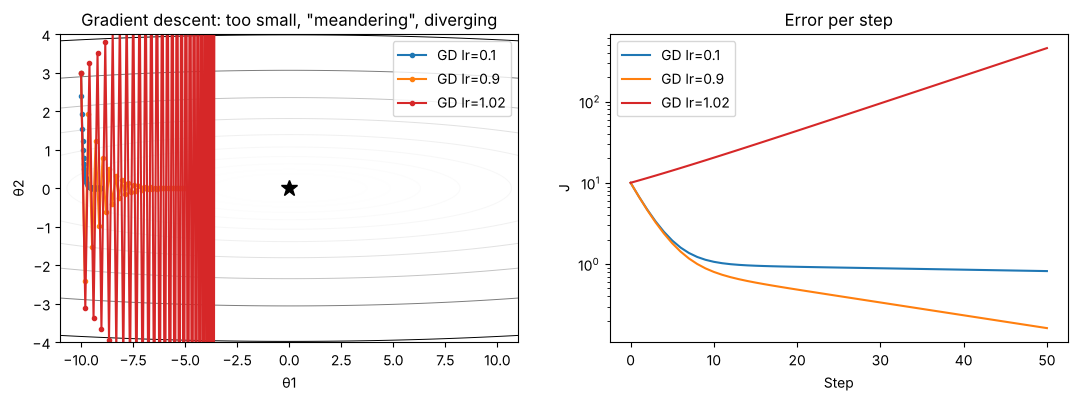

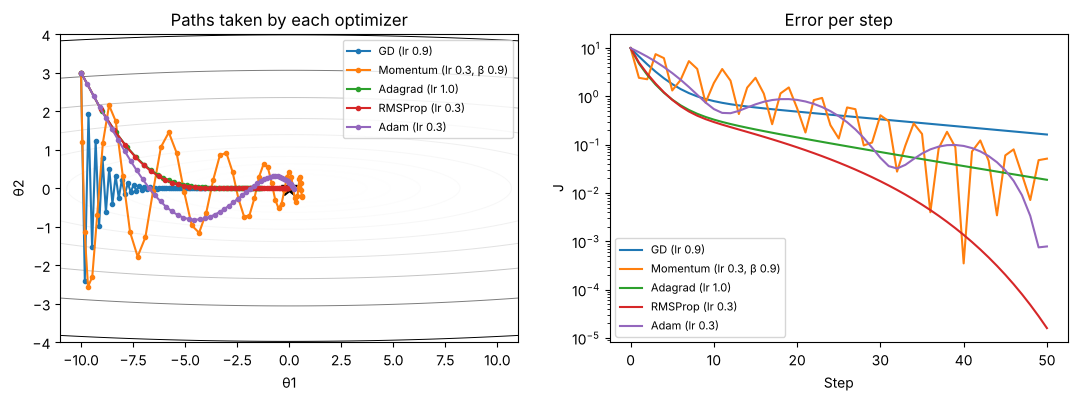

In [10]:
# Error surface (a long narrow valley) and its gradient
def J_valley(t):    return 0.01 * t[0]**2 + t[1]**2
def grad_valley(t): return np.array([0.02 * t[0], 2 * t[1]])

# --- The optimizers, written out in a few lines each ---
def run_gd(grad, t0, lr, steps):
    t, path = np.array(t0, float), [np.array(t0, float)]
    for _ in range(steps):
        t = t - lr * grad(t); path.append(t.copy())
    return np.array(path)

def run_momentum(grad, t0, lr, steps, beta=0.9):
    t, v, path = np.array(t0, float), np.zeros(2), [np.array(t0, float)]
    for _ in range(steps):
        v = beta * v - lr * grad(t); t = t + v; path.append(t.copy())
    return np.array(path)

def run_adagrad(grad, t0, lr, steps, eps=1e-8):
    t, G, path = np.array(t0, float), np.zeros(2), [np.array(t0, float)]
    for _ in range(steps):
        g = grad(t); G += g**2; t = t - lr * g / (np.sqrt(G) + eps); path.append(t.copy())
    return np.array(path)

def run_rmsprop(grad, t0, lr, steps, rho=0.9, eps=1e-8):
    t, s, path = np.array(t0, float), np.zeros(2), [np.array(t0, float)]
    for _ in range(steps):
        g = grad(t); s = rho * s + (1 - rho) * g**2; t = t - lr * g / (np.sqrt(s) + eps); path.append(t.copy())
    return np.array(path)

def run_adam(grad, t0, lr, steps, b1=0.9, b2=0.999, eps=1e-8):
    t, m, s, path = np.array(t0, float), np.zeros(2), np.zeros(2), [np.array(t0, float)]
    for k in range(1, steps + 1):
        g = grad(t)
        m = b1 * m + (1 - b1) * g;  s = b2 * s + (1 - b2) * g**2
        m_hat, s_hat = m / (1 - b1**k), s / (1 - b2**k)
        t = t - lr * m_hat / (np.sqrt(s_hat) + eps); path.append(t.copy())
    return np.array(path)

def valley_contours(ax):
    a, b = np.meshgrid(np.linspace(-11, 11, 200), np.linspace(-4, 4, 200))
    ax.contour(a, b, 0.01 * a**2 + b**2, levels=np.logspace(-2, 1.2, 15), cmap='Greys', linewidths=0.7)
    ax.plot(0, 0, 'k*', ms=12)
    ax.set_xlabel('θ1'); ax.set_ylabel('θ2')

start, steps = [-10.0, 3.0], 50

# 1) The learning rate problem: plain gradient descent with three learning rates
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
valley_contours(axes[0])
for lr, c in [(0.1, 'C0'), (0.9, 'C1'), (1.02, 'C3')]:
    p = run_gd(grad_valley, start, lr, steps)
    axes[0].plot(p[:, 0], p[:, 1], 'o-', ms=3, color=c, label=f'GD lr={lr}')
    axes[1].plot([J_valley(t) for t in p], color=c, label=f'GD lr={lr}')
axes[0].set_ylim(-4, 4); axes[0].set_title('Gradient descent: too small, "meandering", diverging'); axes[0].legend()
axes[1].set_yscale('log'); axes[1].set_xlabel('Step'); axes[1].set_ylabel('J'); axes[1].set_title('Error per step'); axes[1].legend()
plt.show()

# 2) The improved optimizers, all for 50 steps from the same starting point
paths = {'GD (lr 0.9)':           run_gd(grad_valley, start, 0.9, steps),
         'Momentum (lr 0.3, β 0.9)': run_momentum(grad_valley, start, 0.3, steps),
         'Adagrad (lr 1.0)':       run_adagrad(grad_valley, start, 1.0, steps),
         'RMSProp (lr 0.3)':       run_rmsprop(grad_valley, start, 0.3, steps),
         'Adam (lr 0.3)':          run_adam(grad_valley, start, 0.3, steps)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
valley_contours(axes[0])
for i, (name, p) in enumerate(paths.items()):
    axes[0].plot(p[:, 0], p[:, 1], 'o-', ms=3, color=f'C{i}', label=name)
    axes[1].plot([J_valley(t) for t in p], color=f'C{i}', label=name)
axes[0].set_ylim(-4, 4); axes[0].set_title('Paths taken by each optimizer'); axes[0].legend(fontsize=8)
axes[1].set_yscale('log'); axes[1].set_xlabel('Step'); axes[1].set_ylabel('J'); axes[1].set_title('Error per step'); axes[1].legend(fontsize=8)
plt.show()

Things to notice:
 * **Learning rate (top plots):** with $\alpha = 0.1$ gradient descent makes almost no progress along the shallow $\theta_1$ direction. With $\alpha=0.9$ it zig-zags across the valley ("meandering"), because the step is nearly too large for the steep $\theta_2$ direction. Just above $\alpha = 1$ it diverges. The steep direction limits the learning rate, and the shallow direction is then starved.
 * **Momentum** overshoots and swings around the minimum, but it builds up speed along the valley floor and ends up much closer to the minimum than plain gradient descent in the same number of steps.
 * **Adagrad, RMSProp and Adam** rescale each parameter separately. The steep $\theta_2$ direction is damped and the shallow $\theta_1$ direction is boosted, so they first drop straight to the valley floor and then travel along it. Adagrad slows down as its accumulated $G$ grows, and Adam's momentum term makes it overshoot slightly before settling.
 * Every optimizer here has its own learning rate. Try changing them: the adaptive methods are much less sensitive to this choice than plain gradient descent.

### Momentum and Local Minima
The second problem with gradient descent was getting stuck in local minima. Below is a one-dimensional error function with a shallow local minimum on the right and a deeper global minimum on the left. Starting from the right, plain gradient descent settles in the nearest (local) minimum, while momentum carries enough "speed" to roll through it into the deeper one.

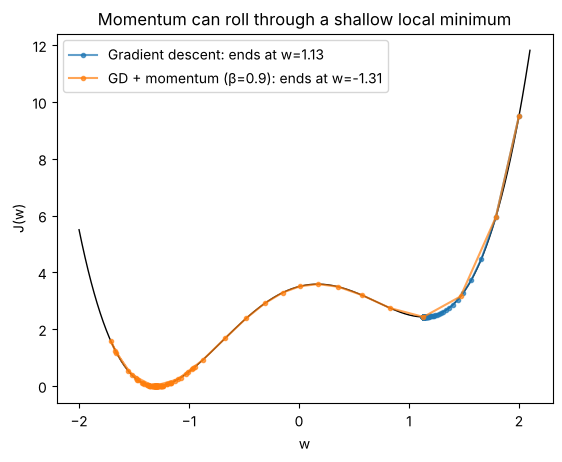

In [11]:
f  = lambda w: w**4 - 3 * w**2 + w + 3.5          # local min near w=1.13, global min near w=-1.30
df = lambda w: 4 * w**3 - 6 * w + 1

def run_1d(lr, steps, beta=0.0, w0=2.0):
    w, v, path = w0, 0.0, [w0]
    for _ in range(steps):
        v = beta * v - lr * df(w); w = w + v; path.append(w)
    return np.array(path)

ws = np.linspace(-2, 2.1, 300)
plt.plot(ws, f(ws), 'k', lw=1)
for name, p, c in [('Gradient descent', run_1d(0.01, 100), 'C0'),
                   ('GD + momentum (β=0.9)', run_1d(0.01, 100, beta=0.9), 'C1')]:
    plt.plot(p, f(p), 'o-', ms=3, color=c, alpha=0.7, label=f'{name}: ends at w={p[-1]:.2f}')
plt.xlabel('w'); plt.ylabel('J(w)'); plt.title('Momentum can roll through a shallow local minimum'); plt.legend(); plt.show()

(Momentum is not *guaranteed* to find the global minimum, and with too much speed it can roll past good minima too. But it makes training much less sensitive to small bumps in the error surface.)

### Running Example: Step 3, Comparing Optimizers
Now we return to the spirals. We use a ReLU network with 2 hidden layers of 64 units and a softmax output, give every optimizer **identical starting weights**, and train each one for 300 epochs. We compare:
 * Full-batch gradient descent (`SGD` with `batch_size=300`, so one update per epoch).
 * Mini-batch SGD (`batch_size=30`, so 10 updates per epoch).
 * Full-batch gradient descent with momentum.
 * Adagrad, RMSProp and Adam (full batch).

Each optimizer has been given a reasonable learning rate. A fair comparison in practice would tune the learning rate for each one separately.

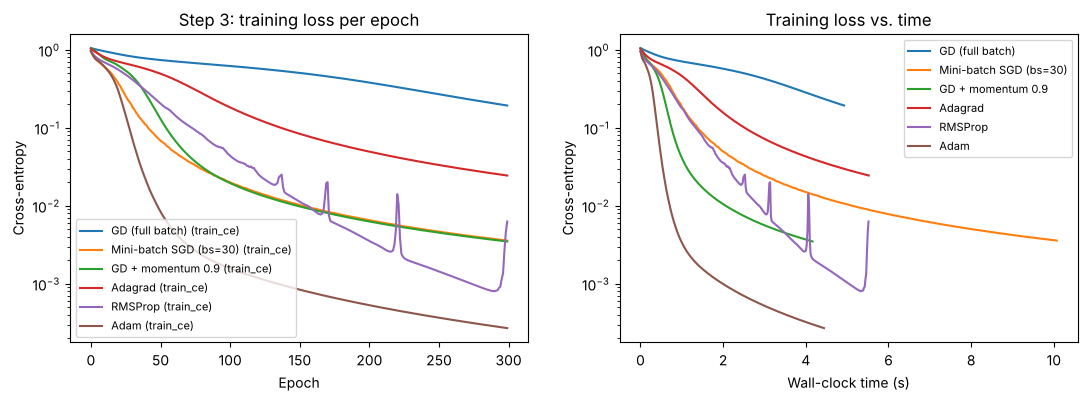

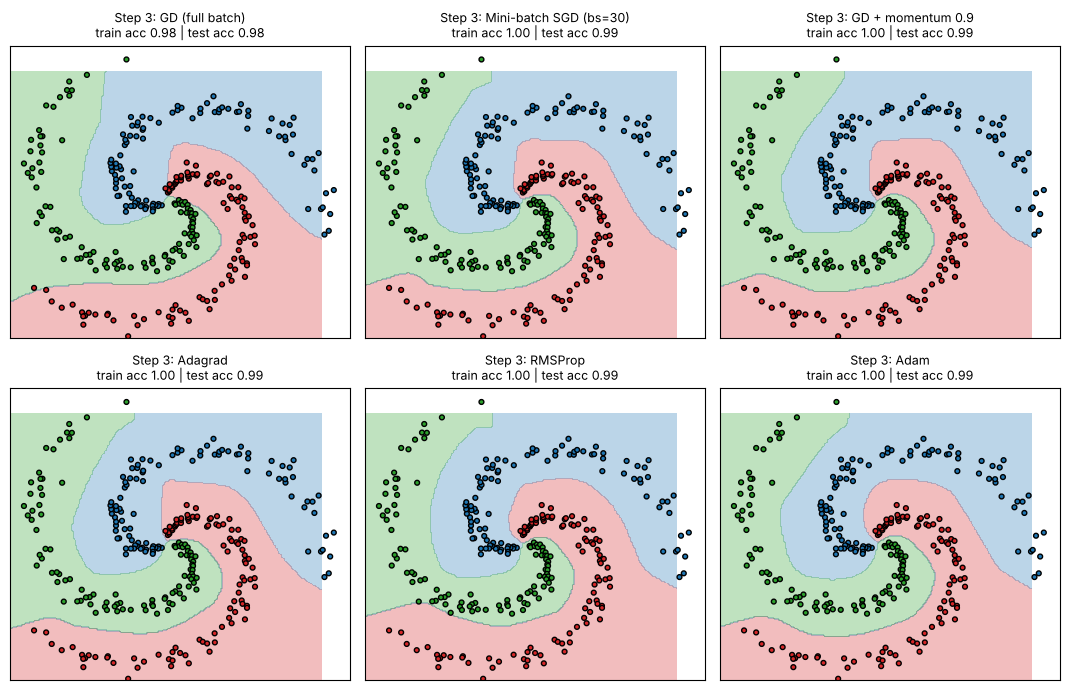

3. Optimizer: GD (full batch)              train acc 0.983 | test acc 0.977 | test loss 0.208
3. Optimizer: Mini-batch SGD (bs=30)       train acc 1.000 | test acc 0.994 | test loss 0.033
3. Optimizer: GD + momentum 0.9            train acc 1.000 | test acc 0.994 | test loss 0.038
3. Optimizer: Adagrad                      train acc 1.000 | test acc 0.993 | test loss 0.049
3. Optimizer: RMSProp                      train acc 1.000 | test acc 0.994 | test loss 0.038
3. Optimizer: Adam                         train acc 1.000 | test acc 0.994 | test loss 0.037


In [12]:
opt_configs = {
    'GD (full batch)':        (lambda: tf.keras.optimizers.SGD(learning_rate=0.1), None),
    'Mini-batch SGD (bs=30)': (lambda: tf.keras.optimizers.SGD(learning_rate=0.1), 30),
    'GD + momentum 0.9':      (lambda: tf.keras.optimizers.SGD(learning_rate=0.1, momentum=0.9), None),
    'Adagrad':                (lambda: tf.keras.optimizers.Adagrad(learning_rate=0.1), None),
    'RMSProp':                (lambda: tf.keras.optimizers.RMSprop(learning_rate=0.003), None),
    'Adam':                   (lambda: tf.keras.optimizers.Adam(learning_rate=0.01), None),
}
opt_models, opt_hists = {}, {}
for name, (make_opt, bs) in opt_configs.items():
    m = build_net(hidden=(64, 64), activation='relu')      # same seed -> same initial weights
    opt_hists[name] = fit_net(m, optimizer=make_opt(), epochs=300, batch_size=bs)
    opt_models[name] = m

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_curves(opt_hists, title='Step 3: training loss per epoch', ax=axes[0])
for i, (name, h) in enumerate(opt_hists.items()):
    t = np.linspace(0, h.seconds, len(h.history['train_ce']))
    axes[1].plot(t, h.history['train_ce'], color=f'C{i}', label=name)
axes[1].set_xlabel('Wall-clock time (s)'); axes[1].set_ylabel('Cross-entropy')
axes[1].set_title('Training loss vs. time'); axes[1].legend(fontsize=8)
for ax in axes: ax.set_yscale('log')
plt.show()
plot_boundaries({f'Step 3: {k}': m for k, m in opt_models.items()}, ncols=3)
for k, m in opt_models.items():
    record(f'3. Optimizer: {k}', m, opt_hists[k])

Typical observations (the exact curves vary from run to run and from problem to problem; note the log scale):
 * **Full-batch gradient descent** is by far the slowest to reduce the loss. Its accuracy looks fine on this easy-to-separate data, but after 300 epochs its loss is still many times higher than the others.
 * **Mini-batch SGD** makes 10 updates per epoch, so its loss falls much faster *per epoch*, but each epoch also takes longer in wall-clock time. Its curve is noisier because each update only sees part of the data.
 * **Momentum** gives a large speed-up over plain gradient descent at almost no extra cost.
 * **Adagrad** starts reasonably quickly but its effective learning rate keeps shrinking. **RMSProp** reaches a low loss quickly but shows occasional spikes where its rescaled steps overshoot. **Adam**, which adds momentum to RMSProp-style scaling, reaches the lowest loss fastest here.

There is no single best optimizer for every problem, so compare them on your own task, as in the comparison figure in the lecture slides. Also remember that a faster fall in *training* loss does not by itself guarantee better performance on new data. Adam is usually a sensible first choice.

---
## Running Example: Step 4, Putting It All Together
Finally we combine what we have learned in this session:
 * a **softmax** output layer for our multi-class problem (Step 1)
 * **Leaky ReLU** hidden units (Step 2)
 * the **Adam** optimizer with **mini-batches** (Step 3).

Because Adam with mini-batches makes fast progress, we only need 100 epochs.

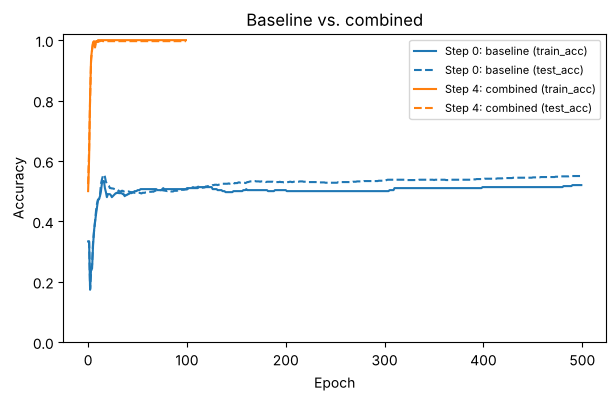

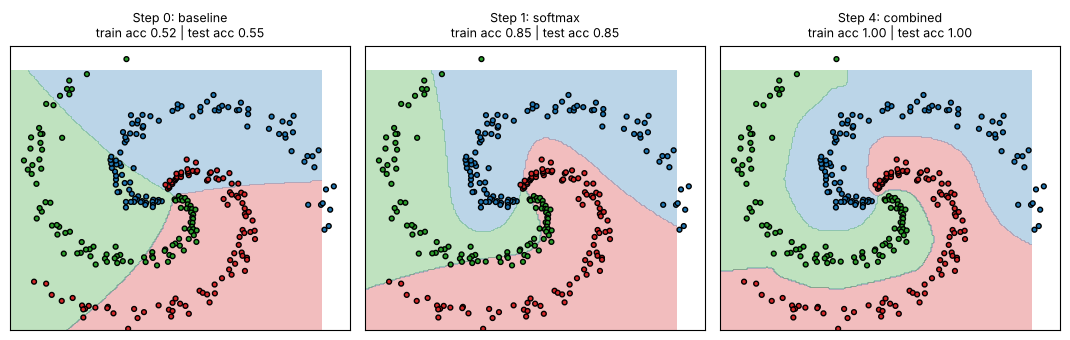

4. Combined (softmax + Leaky ReLU + Adam, mini-batch) train acc 1.000 | test acc 0.997 | test loss 0.035


In [13]:
final = build_net(hidden=(64, 64), activation=leaky_relu, output='softmax')
h_final = fit_net(final, optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), epochs=100, batch_size=30)

plot_curves({'Step 0: baseline': h_base, 'Step 4: combined': h_final}, keys=('train_acc', 'test_acc'),
            title='Baseline vs. combined', ylim=(0, 1.02))
plt.show()
plot_boundaries({'Step 0: baseline': base, 'Step 1: softmax': soft_net, 'Step 4: combined': final}, ncols=3)
record('4. Combined (softmax + Leaky ReLU + Adam, mini-batch)', final, h_final)

### The Scoreboard
Below is every result recorded in the running example. **Test acc** and **test loss** are measured on the 900 test points the networks never trained on. The test loss (cross-entropy) is a more sensitive measure than accuracy: two networks can have the same accuracy, but the one that gives the correct class a higher probability will have a lower loss.

,train acc,test acc,train loss,test loss,train time (s)
"0. Baseline (logistic hidden & outputs, GD)",0.520,0.550,0.757,0.745,6.5
"1. Softmax output (logistic hidden, GD)",0.847,0.852,0.335,0.332,6.5
2. Hidden activation = logistic (GD),0.357,0.360,1.098,1.098,10.8
2. Hidden activation = tanh (GD),1.000,0.997,0.010,0.020,8.9
2. Hidden activation = relu (GD),1.000,0.997,0.008,0.037,10.8
2. Hidden activation = leaky relu (GD),1.000,0.997,0.007,0.039,9.3
3. Optimizer: GD (full batch),0.983,0.977,0.193,0.208,4.9
3. Optimizer: Mini-batch SGD (bs=30),1.000,0.994,0.004,0.033,10.1
3. Optimizer: GD + momentum 0.9,1.000,0.994,0.003,0.038,4.2
3. Optimizer: Adagrad,1.000,0.993,0.024,0.049,5.5


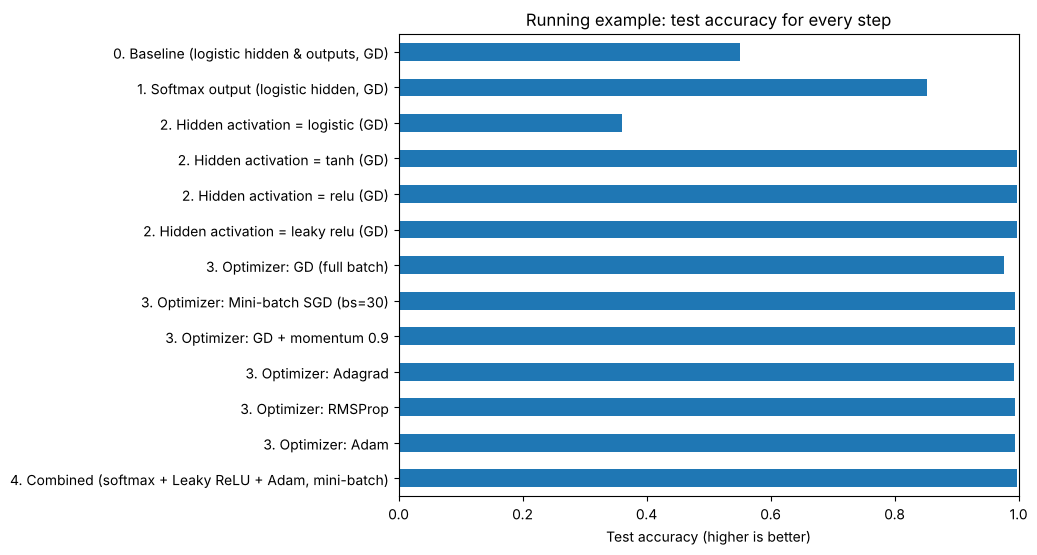

In [14]:
import pandas as pd
board = pd.DataFrame(results).T
display(board.style.format('{:.3f}', subset=['train acc', 'test acc', 'train loss', 'test loss'])
             .format('{:.1f}', subset=['train time (s)'])
             .background_gradient(subset=['test acc'], cmap='RdYlGn'))

board['test acc'].plot.barh(figsize=(8, 6), color='C0')
plt.gca().invert_yaxis(); plt.xlim(0, 1); plt.xlabel('Test accuracy (higher is better)')
plt.title('Running example: test accuracy for every step'); plt.show()

# Questions and Group Assignment

### Questions from the lecture
1. Come up with your own examples of **multi-label** and **multi-class** classification problems.
2. Can we use multinomial (softmax) classification for **multiple real-valued outputs**? Why, or why not?
3. Are softmax output calculations independent of each other? (Look again at the softmax plots in the notebook.)

### Group Assignment: Leaky ReLU vs. Clipped ReLU
Split into small groups. Within your group split in two, parts A and B. Each half has 15 minutes to investigate its variety, and then two minutes to inform the other half of the team. Use the running example, as it trains in seconds.

 * **Part A, Leaky ReLU.** We used $\alpha = 0.01$. Repeat Step 2 and the dying ReLU experiment with larger values of $\alpha$ (e.g. 0.1, 0.3) by changing the `leaky_relu` function. How does $\alpha$ affect training speed, the number of dead units and the class regions? What happens as $\alpha$ approaches 1, and why?
 * **Part B, Clipped ReLU.** A clipped ReLU caps the output at a maximum value: $g(z) = \min(\max(0, z), c)$. Keras provides `tf.nn.relu6` ($c = 6$), or you can write your own with `tf.clip_by_value(z, 0, c)`. Repeat Step 2 with a clipped ReLU, and also try a high learning rate (e.g. 0.5) with both plain and clipped ReLU. Why might clipping help with stability? What is $g'(z)$ for $z > c$, and what problem might this cause?

### Further tasks
1. **Learning-rate sensitivity.** For SGD and Adam, try learning rates of 0.0001, 0.001, 0.01, 0.1 and 1.0 in Step 3. Which optimizer is more forgiving of a badly chosen learning rate?
2. **Batch size.** Repeat the mini-batch SGD experiment with batch sizes 1 (pure stochastic gradient descent), 10, 30 and 100. Compare the loss per epoch *and* the loss per second.
3. **Multi-label outputs.** Make a multi-label version of the problem, e.g. label each point with two yes/no labels: "is it in the red spiral?" and "is it outside the unit circle?". Which output activation and loss should you use, and why would softmax be wrong here?

# Doing Things the Easy Way

Everything above was explained step by step. In practice, a deep learning library hands us all of these ideas ready-made: each one is usually a **one-line change**. This section reruns the same spirals example in **PyTorch** and quickly works through the same ideas: output activations, hidden activations, dying ReLU, and optimizers. The explanations above still apply; here we just change a line and look at the result.

We reuse the spirals data (`Xtr`, `ytr`, `Xte`, `yte`) from the running example, so make sure the running-example cells near the top have been run.

In [4]:
import torch
import torch.nn as nn
import pandas as pd

torch_X,  torch_y  = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.long)
torch_Xt, torch_yt = torch.tensor(Xte), torch.tensor(yte, dtype=torch.long)

def mlp(hidden=(64, 64), act=nn.ReLU, n_out=3, seed=0):
    # Build Linear -> activation -> ... -> Linear. The output layer has NO activation:
    # PyTorch's loss functions take the raw logits and apply sigmoid / softmax internally.
    torch.manual_seed(seed)
    layers, n_in = [], 2
    for h in hidden:
        layers += [nn.Linear(n_in, h), act()]
        n_in = h
    return nn.Sequential(*layers, nn.Linear(n_in, n_out))

def train(model, opt, loss_fn=nn.CrossEntropyLoss(), epochs=300, batch_size=None, scheduler=None, one_hot=False):
    targets = nn.functional.one_hot(torch_y, 3).float() if one_hot else torch_y
    n, bs, losses = len(torch_X), batch_size or len(torch_X), []
    for epoch in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, bs):                       # one update per mini-batch
            idx = perm[i:i + bs]
            opt.zero_grad()                             # clear old gradients
            loss = loss_fn(model(torch_X[idx]), targets[idx])
            loss.backward()                             # backpropagation
            opt.step()                                  # apply the optimizer's update rule
        if scheduler: scheduler.step()
        with torch.no_grad():
            losses.append(nn.functional.cross_entropy(model(torch_X), torch_y).item())
    return losses

def test_acc(model):
    with torch.no_grad():
        return (model(torch_Xt).argmax(1) == torch_yt).float().mean().item()

def show(models, losses, title):
    n = len(models) + 1; ncols = min(n, 4); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.3 * nrows), squeeze=False)
    axes = axes.ravel()
    for ax in axes[n:]: ax.axis('off')
    for name, l in losses.items():
        axes[0].plot(l, label=name)
    axes[0].set_yscale('log'); axes[0].set_title(title, fontsize=9); axes[0].set_xlabel('Epoch'); axes[0].legend(fontsize=7)
    for ax, (name, m) in zip(axes[1:], models.items()):
        with torch.no_grad():
            cls = m(torch.tensor(_grid)).argmax(1).numpy().reshape(_g1.shape)
        ax.contourf(_g1, _g2, cls, levels=[-0.5, 0.5, 1.5, 2.5], cmap=CMAP, alpha=0.3)
        ax.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap=CMAP, s=6)
        ax.set_title(f'{name}\ntest acc {test_acc(m):.3f}', fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

torch_results = {}

### 1. Output activations: independent logistic outputs vs. softmax
The output activation is chosen through the **loss function**: `BCEWithLogitsLoss` applies a logistic function to each output independently (multi-label style), while `CrossEntropyLoss` applies a softmax (multi-class). Same network, same optimizer.

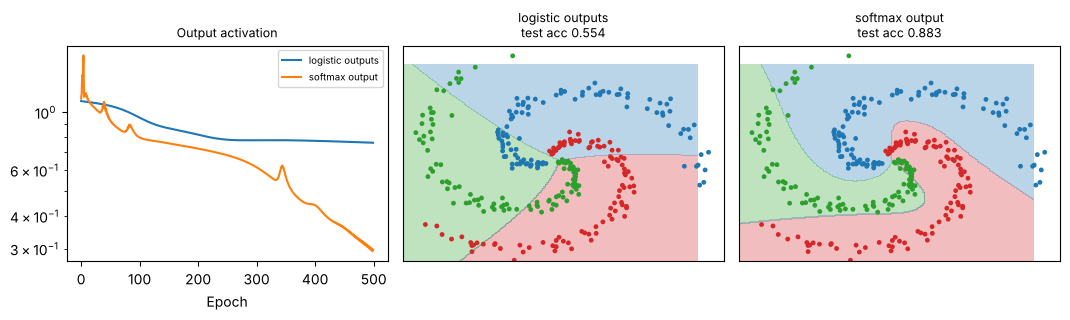

In [5]:
models, losses = {}, {}
for name, loss_fn, one_hot in [('logistic outputs', nn.BCEWithLogitsLoss(), True),
                               ('softmax output',   nn.CrossEntropyLoss(),  False)]:
    m = mlp(hidden=(32, 32), act=nn.Sigmoid)
    losses[name] = train(m, torch.optim.SGD(m.parameters(), lr=1.0), loss_fn, epochs=500, one_hot=one_hot)
    models[name] = m; torch_results[f'1. {name}'] = test_acc(m)
show(models, losses, 'Output activation')

### 2. Hidden activations
Each activation is just a different layer class. We also try two you have not seen yet: `ReLU6` (a **clipped ReLU**, capped at 6, as in the group assignment) and `GELU` (a smooth ReLU-like function used in transformers). Deep network (4 hidden layers), plain SGD.

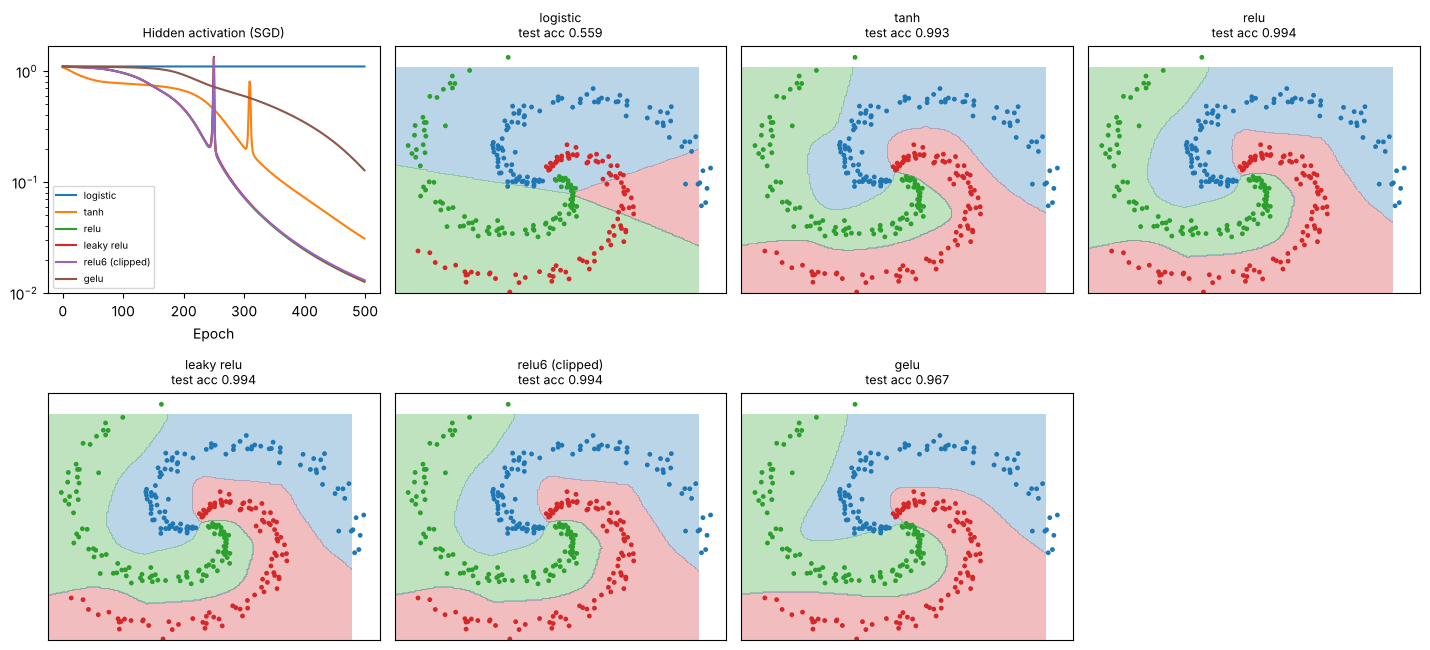

In [6]:
acts = {'logistic': nn.Sigmoid, 'tanh': nn.Tanh, 'relu': nn.ReLU,
        'leaky relu': lambda: nn.LeakyReLU(0.01), 'relu6 (clipped)': nn.ReLU6, 'gelu': nn.GELU}
models, losses = {}, {}
for name, act in acts.items():
    m = mlp(hidden=(32, 32, 32, 32), act=act)
    losses[name] = train(m, torch.optim.SGD(m.parameters(), lr=0.1), epochs=500)
    models[name] = m; torch_results[f'2. {name}'] = test_acc(m)
show(models, losses, 'Hidden activation (SGD)')

### 3. Dying ReLU
Start every hidden bias at -2 so that every unit begins "dead" (PyTorch's default weights are smaller than Keras's, so we need a more negative bias than above), then count the units whose input is negative for every training point.

relu       dead units: 100% -> 100%


leaky relu dead units: 100% -> 19%


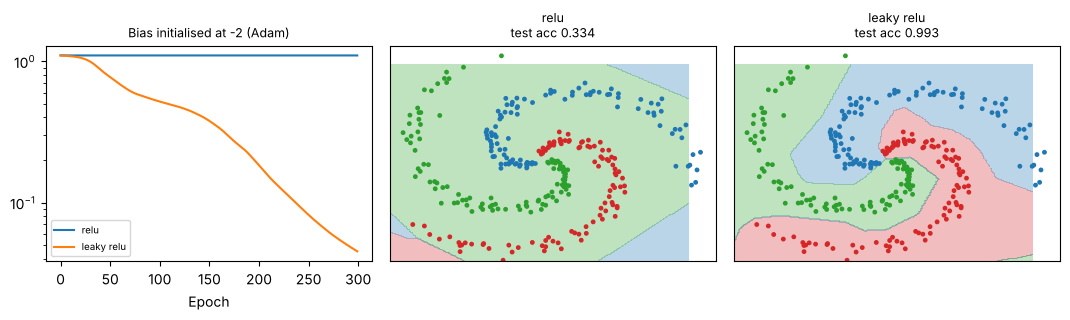

In [7]:
def dead(model):
    with torch.no_grad():
        return ((model[0](torch_X) <= 0).all(dim=0)).float().mean().item()

models, losses = {}, {}
for name, act in [('relu', nn.ReLU), ('leaky relu', lambda: nn.LeakyReLU(0.01))]:
    m = mlp(hidden=(32,), act=act)
    nn.init.constant_(m[0].bias, -2.0)
    before = dead(m)
    losses[name] = train(m, torch.optim.Adam(m.parameters(), lr=0.01))
    print(f'{name:10s} dead units: {before:.0%} -> {dead(m):.0%}')
    models[name] = m; torch_results[f'3. dying test: {name}'] = test_acc(m)
show(models, losses, 'Bias initialised at -2 (Adam)')

### 4. Optimizers
Every optimizer from the slides is one line in `torch.optim`. We also show an **adjustable learning rate**: a scheduler that smoothly lowers SGD's learning rate during training (`CosineAnnealingLR`).

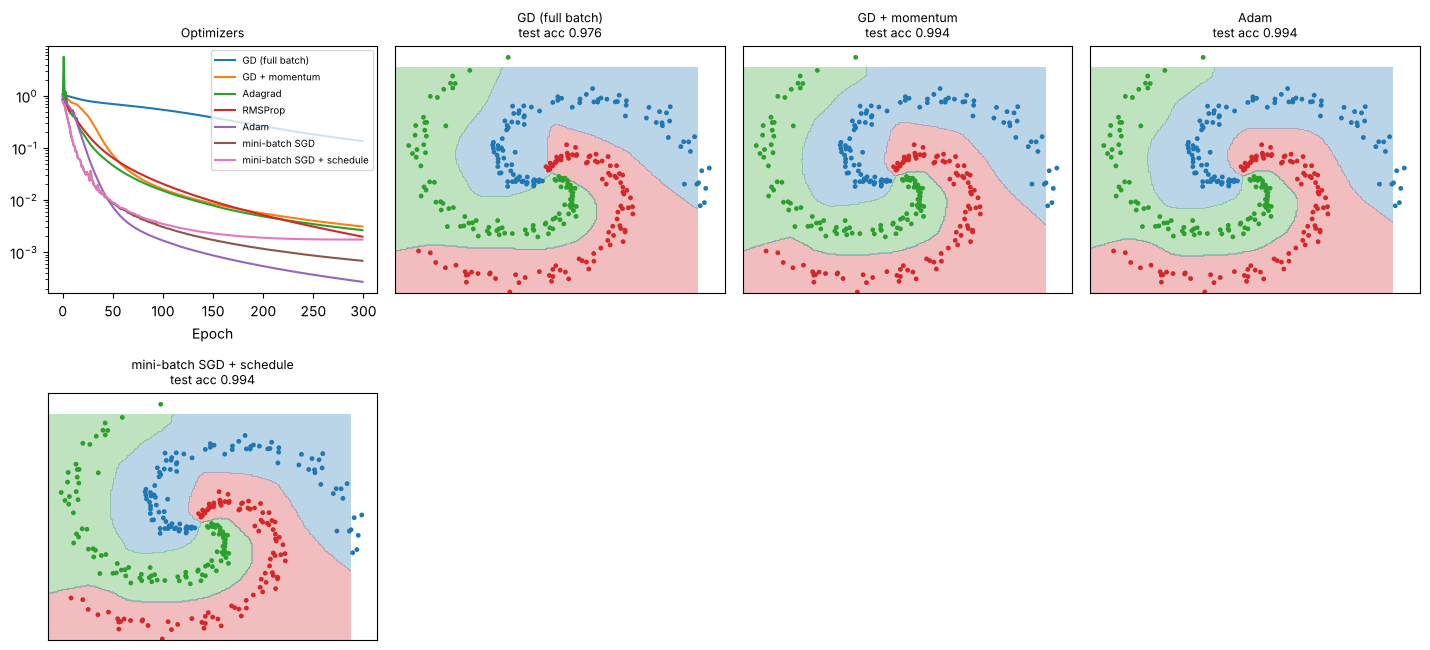

In [8]:
opts = {
    'GD (full batch)':     lambda p: torch.optim.SGD(p, lr=0.1),
    'GD + momentum':       lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9),
    'Adagrad':             lambda p: torch.optim.Adagrad(p, lr=0.1),
    'RMSProp':             lambda p: torch.optim.RMSprop(p, lr=0.003),
    'Adam':                lambda p: torch.optim.Adam(p, lr=0.01),
}
models, losses = {}, {}
for name, make_opt in opts.items():
    m = mlp()
    losses[name] = train(m, make_opt(m.parameters()))
    models[name] = m; torch_results[f'4. {name}'] = test_acc(m)

# Mini-batch SGD, and mini-batch SGD with a learning-rate schedule
for name, sched in [('mini-batch SGD', False), ('mini-batch SGD + schedule', True)]:
    m = mlp(); opt = torch.optim.SGD(m.parameters(), lr=0.3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=300) if sched else None
    losses[name] = train(m, opt, batch_size=30, scheduler=scheduler)
    models[name] = m; torch_results[f'4. {name}'] = test_acc(m)

show({k: models[k] for k in ['GD (full batch)', 'GD + momentum', 'Adam', 'mini-batch SGD + schedule']}, losses, 'Optimizers')

### 5. Everything together, and the scoreboard
Softmax output + Leaky ReLU + Adam with mini-batches, in just a few lines.

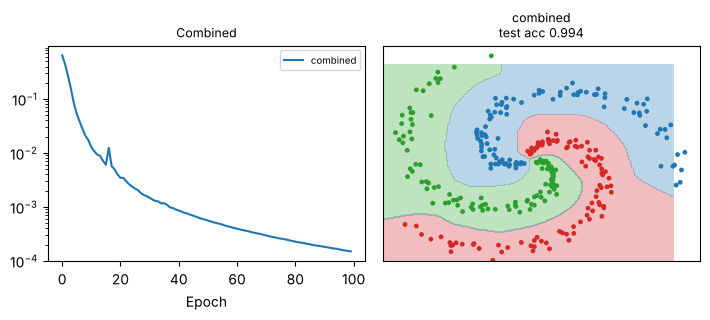

,test accuracy
1. logistic outputs,0.554
1. softmax output,0.883
2. logistic,0.559
2. tanh,0.993
2. relu,0.994
2. leaky relu,0.994
2. relu6 (clipped),0.994
2. gelu,0.967
3. dying test: relu,0.334
3. dying test: leaky relu,0.993


In [9]:
final_t = mlp(act=lambda: nn.LeakyReLU(0.01))
l = train(final_t, torch.optim.Adam(final_t.parameters(), lr=0.01), epochs=100, batch_size=30)
torch_results['5. softmax + leaky relu + Adam (mini-batch)'] = test_acc(final_t)
show({'combined': final_t}, {'combined': l}, 'Combined')

pd.Series(torch_results, name='test accuracy').to_frame().style.format('{:.3f}').background_gradient(cmap='RdYlGn')